# Squirrel Multiclass Detection · RF-DETR Medium (v2)

One notebook: **secure setup → dataset audit & EDA → ClearML → GPU probe → 50-epoch training → validation → test → exported weights**.

**Decisions:**
- **11 Classes:** 10 focal squirrel species + `generic_squirrel`
  1. `Callosciurus erythraeus` (Pallas's squirrel)
  2. `Sciurus aureogaster` (Mexican gray squirrel)
  3. `Sciurus carolinensis` (Eastern gray squirrel)
  4. `Sciurus granatensis` (Red-tailed squirrel)
  5. `Sciurus griseus` (Western gray squirrel)
  6. `Sciurus lis` (Japanese squirrel)
  7. `Sciurus niger` (Fox squirrel)
  8. `Sciurus vulgaris` (Eurasian red squirrel)
  9. `Tamiasciurus douglasii` (Douglas squirrel)
  10. `Tamiasciurus hudsonicus` (American red squirrel)
  11. `generic_squirrel` (unresolved species or other squirrels; some human-reviewed source-label overrides)
- **Dataset:** `data/squirrel-v2-audited-coco`, created after the species-purity and leakage audit passes.
- **Split Distribution:** Group-isolated train, validation and test splits; counts come from the audited manifest.
- **Leakage Prevention:** Strict grouping by `group_id` (burst sequences and iNaturalist observations are strictly isolated to a single split). Bursts with $>4$ images are isolated into `train`.
- **Model:** RF-DETR Medium with multiclass classification head (11 classes).
- **Seed:** 42; batch/accumulation sequence **8×2, 4×4, 4×2**.

## Run instructions
From the repository: `uv sync --locked`, then launch Jupyter and run cells in order.
Credentials belong in `.env`. Reports and checkpoints are generated under `output/runs/`.


In [1]:
# 1. Configuration — edit only nonsecret experiment settings here.
from pathlib import Path
import os, sys, json, re, io, time, uuid, hashlib, shutil, zipfile, contextlib
import math, random, gc, logging, traceback, html, platform, importlib.metadata
from datetime import datetime, timezone

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Launch Jupyter from the repository."

CFG = dict(
    seed=42,
    project="squirrel-multiclass-v2",
    version=2,
    num_classes=11,
    epochs=50,
    resolution=576,
    lr=1e-4,
    eval_batch_size=2,
    batch_candidates=[[8, 2], [4, 4], [4, 2]],
    clearml_project="CSCI-635-Squirrel-Multiclass-v2",
    prediction_floor=0.0001,
    iou=0.5,
    max_detections=100,
    leakage_max_distance=4,  # pHash Hamming threshold knob (0=exact pHash, 2=tight burst, 4=balanced)
)

RESUME_RUN = None  # e.g. ROOT / 'output/runs/<run-id>'; never resume from lightweight .pth.
LEAKAGE_FALSE_POSITIVES = {}

DATA = ROOT / "data/squirrel-v2-audited-coco"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-v2-" + uuid.uuid4().hex[:6]
RUN = Path(RESUME_RUN).resolve() if RESUME_RUN else ROOT / "output/runs" / RUN_ID
REPORT = RUN / "reports"
for path in (DATA.parent, REPORT): path.mkdir(parents=True, exist_ok=True)

latest_symlink = ROOT / "output/runs/latest"
try:
    if latest_symlink.is_symlink() or latest_symlink.exists(): latest_symlink.unlink()
    latest_symlink.symlink_to(RUN, target_is_directory=True)
except Exception:
    pass

os.environ["RF_HOME"] = str(ROOT / "output/pretrained")
from dotenv import load_dotenv
load_dotenv(ROOT / ".env", override=False)

SECRET_NAMES = ("ROBOFLOW_KEY", "ROBOFLOW_API_KEY", "CLEARML_API_ACCESS_KEY", "CLEARML_API_SECRET_KEY", "CLEARML_TOKEN")
from urllib.parse import quote, quote_plus
_SECRETS = sorted({v for k in SECRET_NAMES if os.environ.get(k) for v in (os.environ[k], quote(os.environ[k], safe=""), quote_plus(os.environ[k]))}, key=len, reverse=True)

def redact(value):
    text = str(value)
    for secret in sorted(_SECRETS, key=len, reverse=True):
        text = text.replace(secret, "[REDACTED]")
    text = re.sub(r"https?://[^\s\"\'<>]+", lambda m: m[0].split("?")[0] + ("?[REDACTED]" if "?" in m[0] else ""), text)
    return text

def assert_secret_free(value):
    text = value if isinstance(value, str) else json.dumps(value, default=str)
    if any(s in text for s in _SECRETS):
        raise RuntimeError("Secret scan failed; payload was not saved or uploaded.") from None

def save_json(path, value):
    text = json.dumps(value, indent=2, default=str, allow_nan=False)
    assert_secret_free(text)
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(text)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""): h.update(block)
    return h.hexdigest()

class SafeWriter(io.TextIOBase):
    def __init__(self, target): self.target, self.pending = target, ""
    def write(self, text):
        self.pending += text
        while "\n" in self.pending:
            line, self.pending = self.pending.split("\n", 1)
            safe = redact(line) + "\n"
            self.target.write(safe)
            with (RUN / "console.log").open("a") as f: f.write(safe)
        return len(text)
    def flush(self): self.target.flush()
    def finish(self):
        if self.pending: self.write("\n")
        self.flush()

@contextlib.contextmanager
def safe_stage(name):
    out, err = SafeWriter(sys.stdout), SafeWriter(sys.stderr)
    try:
        with contextlib.redirect_stdout(out), contextlib.redirect_stderr(err): yield
    except Exception as exc:
        summary = redact(f"{name}: {type(exc).__name__}: {exc}")
        with (RUN / "errors.log").open("a") as f: f.write(summary + "\n")
        raise RuntimeError(summary) from None
    finally:
        out.finish(); err.finish()

required = ["CLEARML_API_ACCESS_KEY", "CLEARML_API_SECRET_KEY"]
missing = [k for k in required if not os.getenv(k)]
if missing:
    print(f"Note: Missing optional ClearML credentials: {missing}. Training can still run locally.")

os.environ.pop("__SQUIRREL_NO_ENV_CAPTURE__", None)
os.environ["CLEARML_LOG_ENVIRONMENT"] = "__SQUIRREL_NO_ENV_CAPTURE__"
os.environ["CLEARML_NO_DEFAULT_SERVER"] = "1"
os.environ["CLEARML_API_HOST"] = os.getenv("CLEARML_API_HOST", "https://api.clear.ml")
os.environ["CLEARML_WEB_HOST"] = os.getenv("CLEARML_WEB_HOST", "https://app.clear.ml")
os.environ["CLEARML_FILES_HOST"] = os.getenv("CLEARML_FILES_HOST", "https://files.clear.ml")
os.environ["CLEARML_AGENT_LOG_ENVIRONMENT"] = ""
print("Environment and secrets initialized. Run ID:", RUN.name)


Environment and secrets initialized. Run ID: 20260926T153802Z-v2-f35e9e


In [2]:
# Imports and actual GPU test.
with safe_stage("environment"):
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
    import torch, requests, imagehash
    from PIL import Image, ImageDraw
    from IPython.display import display, HTML
    from sklearn.metrics import confusion_matrix
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    from rfdetr import RFDETRMedium
    from rfdetr.config import RFDETRMediumConfig, TrainConfig
    from rfdetr.training import RFDETRDataModule, RFDETRModelModule, build_trainer
    from pytorch_lightning import Callback, seed_everything
    assert importlib.metadata.version("rfdetr") == "1.10.1", "Run uv sync --locked."
    assert torch.cuda.is_available(), "A CUDA GPU is required for this workflow."
    seed_everything(CFG["seed"], workers=True)
    x = torch.randn(64, 64, device="cuda", requires_grad=True)
    x.square().mean().backward(); torch.cuda.synchronize(); del x
    versions = {p: importlib.metadata.version(p) for p in ["rfdetr", "torch", "torchvision", "numpy", "pycocotools"]}
    environment = dict(python=platform.python_version(), packages=versions, cuda=torch.version.cuda,
                       gpu=torch.cuda.get_device_name(), free_vram_gib=torch.cuda.mem_get_info()[0] / 2**30)
    save_json(RUN / "environment.json", environment)
    if RESUME_RUN:
        saved = json.loads((RUN / "config.json").read_text())
        assert saved == CFG, "Resume requires identical configuration."
    else: save_json(RUN / "config.json", CFG)
    print("Environment verified:", environment)


/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Seed set to 42


Environment verified: {'python': '3.13.15', 'packages': {'rfdetr': '1.10.1', 'torch': '2.14.0', 'torchvision': '0.29.0', 'numpy': '2.3.5', 'pycocotools': '2.0.11'}, 'cuda': '13.0', 'gpu': 'NVIDIA GeForce RTX 5060 Ti', 'free_vram_gib': 14.39892578125}


## 2. Dataset verification and integrity audit
Training requires the versioned `data/squirrel-v2-audited-coco` export and its passing QA manifest. Run the dataset audit and export pipeline first. This notebook never builds or repairs a dataset implicitly.


In [3]:
def check_space(required=0, where=DATA.parent):
    free = shutil.disk_usage(where).free
    if free < required + 5 * 2**30:
        raise RuntimeError("Insufficient disk space; free additional storage before rerunning.")

def verify_dataset():
    marker = DATA / ".complete.json"
    assert marker.is_file(), f"Audited dataset missing at {DATA}; complete the QA/export pipeline before training."

    manifest = json.loads(marker.read_text())
    assert manifest["version"] == 3, f"Expected audited export version 3, got {manifest['version']}"
    assert manifest["num_classes"] == CFG["num_classes"], f"Expected {CFG['num_classes']} classes, got {manifest['num_classes']}"
    assert manifest.get("qa_status") == "passed", "Dataset QA has not passed; training blocked."
    assert manifest.get("source_fingerprint"), "Audited dataset has no source fingerprint."
    assert manifest.get("source_image_fingerprint"), "Audited dataset has no source image fingerprint."
    assert manifest.get("audit_decisions_sha256"), "Audited dataset has no audit decision hash."
    assert len(manifest["categories"]) == CFG["num_classes"]

    for split in ["train", "valid", "test"]:
        ann_file = DATA / split / "_annotations.coco.json"
        assert ann_file.exists(), f"Missing {split} annotation file"
        expected_hash = manifest["annotation_hashes"][split]
        assert sha256(ann_file) == expected_hash, f"{split} annotation hash mismatch against manifest marker."
        doc = json.loads(ann_file.read_text())
        category_map = {int(c["id"]): c["name"] for c in doc["categories"]}
        assert category_map == {i + 1: name for i, name in enumerate(manifest["categories"])}, (
            f"{split}: COCO IDs must be 1..11 in model label order 0..10"
        )
        assert {int(a["category_id"]) for a in doc["annotations"]} == set(category_map), (
            f"{split}: all 11 classes need annotations for stable label mapping"
        )

    print("Dataset verified successfully at:", DATA)
    return manifest

with safe_stage("dataset verification"):
    manifest = verify_dataset()
    save_json(RUN / "dataset_manifest.json", manifest)
    print(f"Splits: train={manifest['split_counts']['train']}, valid={manifest['split_counts']['valid']}, test={manifest['split_counts']['test']}")
    print(f"Classes ({len(manifest['categories'])}):", manifest["categories"])


Dataset verified successfully at: /home/ss3813/github/ML/CSCI-635-ML-Project/data/squirrel-v2-audited-coco
Splits: train=5988, valid=1282, test=1284
Classes (11): ['Callosciurus erythraeus', 'Sciurus aureogaster', 'Sciurus carolinensis', 'Sciurus granatensis', 'Sciurus griseus', 'Sciurus lis', 'Sciurus niger', 'Sciurus vulgaris', 'Tamiasciurus douglasii', 'Tamiasciurus hudsonicus', 'generic_squirrel']


In [4]:
def xywh_to_xyxy(box):
    x, y, w, h = map(float, box)
    return [x, y, x + w, y + h]

def audit_dataset():
    splits, records, boxes, problems = {}, [], [], []
    canonical_categories = None

    for split in ["train", "valid", "test"]:
        doc = json.loads((DATA / split / "_annotations.coco.json").read_text())
        assert doc["images"], f"{split}: empty split"
        assert len({i["id"] for i in doc["images"]}) == len(doc["images"]), "Duplicate image IDs"
        assert len({a["id"] for a in doc["annotations"]}) == len(doc["annotations"]), "Duplicate annotation IDs"

        cat_names = [c["name"] for c in sorted(doc["categories"], key=lambda c: int(c["id"]))]
        if canonical_categories is None:
            canonical_categories = cat_names
            assert len(canonical_categories) == CFG["num_classes"], f"Expected {CFG['num_classes']} categories"
        else:
            assert cat_names == canonical_categories, f"Category mismatch in {split}"

        categories_by_id = {int(c["id"]): c["name"] for c in doc["categories"]}
        used = {int(a["category_id"]) for a in doc["annotations"]}
        assert used.issubset(set(categories_by_id)), f"Unknown category IDs in {split}"

        split_images = {}
        for item in doc["images"]:
            path = (DATA / split / item["file_name"]).resolve()
            assert path.is_file(), f"Missing file: {path}"
            assert path.is_relative_to((DATA / split).resolve()), "Unsafe image path"
            try:
                with Image.open(path) as im:
                    im.load()
                    rgb = im.convert("RGB")
                    width, height = rgb.size
                assert (width, height) == (item["width"], item["height"]), "Dimension mismatch"
                pixel_hash = hashlib.sha256(f"{width}x{height}".encode() + rgb.tobytes()).hexdigest()
                phash = str(imagehash.phash(rgb))
                group_id = item.get("group_id") or item.get("source_image_id") or item["file_name"]
                species_label = item.get("species_label", "unknown")

                row = dict(split=split, image_id=item["id"], file_name=item["file_name"], path=str(path),
                           width=width, height=height, pixel_hash=pixel_hash, phash=phash,
                           group_id=group_id, species_label=species_label, objects=0, gt=[])
                split_images[item["id"]] = row
            except Exception as e:
                problems.append(f"{split}: image {item['id']} unreadable: {e}")

        for ann in doc["annotations"]:
            row = split_images.get(ann["image_id"])
            if row is None:
                problems.append(f"{split}: orphan annotation {ann['id']}")
                continue
            b = ann.get("bbox", [])
            valid = len(b) == 4 and all(math.isfinite(float(x)) for x in b)
            if valid:
                x, y, w, h = map(float, b)
                valid = x >= 0 and y >= 0 and w > 0 and h > 0 and (x + w) <= row["width"] + 0.05 and (y + h) <= row["height"] + 0.05
            if not valid:
                problems.append(f"{split}: invalid box {ann['id']} on image {ann['image_id']}")
                continue

            cid = int(ann["category_id"])
            cname = categories_by_id[cid]
            row["objects"] += 1
            row["gt"].append(dict(box=xywh_to_xyxy(b), category_id=cid, class_name=cname))
            boxes.append(dict(split=split, image_id=row["image_id"], category_id=cid, class_name=cname,
                               area=w*h, width=w, height=h, aspect=w/h,
                               cx=(x+w/2)/row["width"], cy=(y+h/2)/row["height"],
                               relative_area=w*h/(row["width"]*row["height"])))

        records.extend(split_images.values())
        splits[split] = doc

    save_json(REPORT / "integrity.json", {"problems": problems})
    if problems:
        raise RuntimeError(f"{len(problems)} data-integrity issues found; see integrity.json. No training permitted.")
    return splits, records, pd.DataFrame(boxes), canonical_categories

def find_leakage_pairs(records, max_distance=None):
    if max_distance is None:
        max_distance = CFG.get("leakage_max_distance", 4)
    split_arr = np.array([r["split"] for r in records])
    group_arr = np.array([r.get("group_id", "") for r in records])
    hashes = np.array([int(r["phash"], 16) for r in records], dtype=np.uint64)
    popcount = np.array([int(x).bit_count() for x in range(256)], dtype=np.uint8)
    pairs = []

    for i, r in enumerate(records):
        idx = np.flatnonzero((np.arange(len(records)) > i) & (split_arr != r["split"]))
        if not len(idx): continue
        xor = (hashes[idx] ^ hashes[i]).view(np.uint8).reshape(-1, 8)
        distances = popcount[xor].sum(axis=1)

        near = set(idx[distances <= max_distance].tolist())
        r_group = r.get("group_id", "")
        if r_group:
            for j in idx[group_arr[idx] == r_group]:
                near.add(int(j))
        for j in idx:
            if records[j]["pixel_hash"] == r["pixel_hash"]:
                near.add(int(j))

        for j in sorted(near):
            other = records[j]
            dist = (int(hashes[i]) ^ int(hashes[j])).bit_count()
            exact_pixels = other["pixel_hash"] == r["pixel_hash"]
            same_group = bool(r_group and other.get("group_id") == r_group)
            confirmed = exact_pixels or same_group
            reason = "identical pixels" if exact_pixels else ("group_id burst leak" if same_group else "perceptual similarity")
            pair_id = hashlib.sha256((r["split"] + "/" + r["file_name"] + "|" + other["split"] + "/" + other["file_name"]).encode()).hexdigest()[:16]
            pairs.append(dict(pair_id=pair_id, left=i, right=j, confirmed=confirmed, reason=reason, distance=dist))

    return pairs

with safe_stage("audit"):
    splits, records, box_df, CLASS_NAMES = audit_dataset()
    image_df = pd.DataFrame([{k: v for k, v in r.items() if k != "gt"} for r in records])
    image_df.to_csv(REPORT / "image_inventory.csv", index=False)
    box_df.to_csv(REPORT / "box_inventory.csv", index=False)
    pairs = find_leakage_pairs(records)
    save_json(REPORT / "leakage_pairs.json", pairs)
    leakage_fingerprint = hashlib.sha256(json.dumps({"manifest": manifest, "images": [(r["split"], r["file_name"], r["pixel_hash"]) for r in records]}, sort_keys=True).encode()).hexdigest()
    confirmed_burst_pairs = [p for p in pairs if p["confirmed"]]
    print(f"Integrity passed. Total images: {len(records)}, Total boxes: {len(box_df)}")
    print(f"Classes ({len(CLASS_NAMES)}): {CLASS_NAMES}")
    print(f"Cross-split candidate pairs: {len(pairs)} (Confirmed group/pixel leaks: {len(confirmed_burst_pairs)})")


Integrity passed. Total images: 8554, Total boxes: 9109
Classes (11): ['Callosciurus erythraeus', 'Sciurus aureogaster', 'Sciurus carolinensis', 'Sciurus granatensis', 'Sciurus griseus', 'Sciurus lis', 'Sciurus niger', 'Sciurus vulgaris', 'Tamiasciurus douglasii', 'Tamiasciurus hudsonicus', 'generic_squirrel']
Cross-split candidate pairs: 0 (Confirmed group/pixel leaks: 0)


## 3. Multiclass EDA and leakage review
Visualizations, distributions, and class representation across the 11 classes.
Green boxes show ground truth annotations color-coded or labelled with the species class name.


,images,objects
split,,
test,1284,1380
train,5988,6379
valid,1282,1350


split,train,valid,test,total
class_name,,,,
Callosciurus erythraeus,533,111,121,765
Sciurus aureogaster,570,122,123,815
Sciurus carolinensis,692,151,157,1000
Sciurus granatensis,566,123,124,813
Sciurus griseus,655,133,132,920
Sciurus lis,449,96,94,639
Sciurus niger,606,124,126,856
Sciurus vulgaris,564,120,126,810
Tamiasciurus douglasii,591,127,131,849


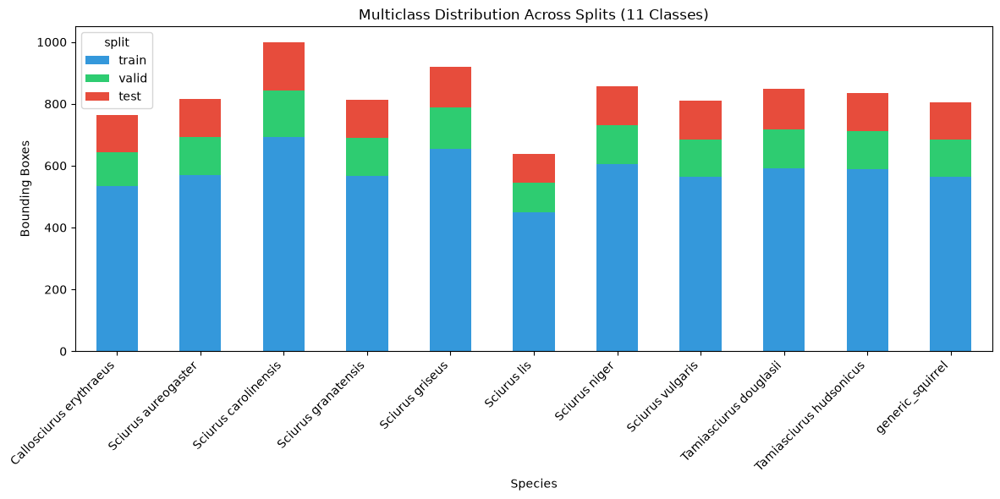

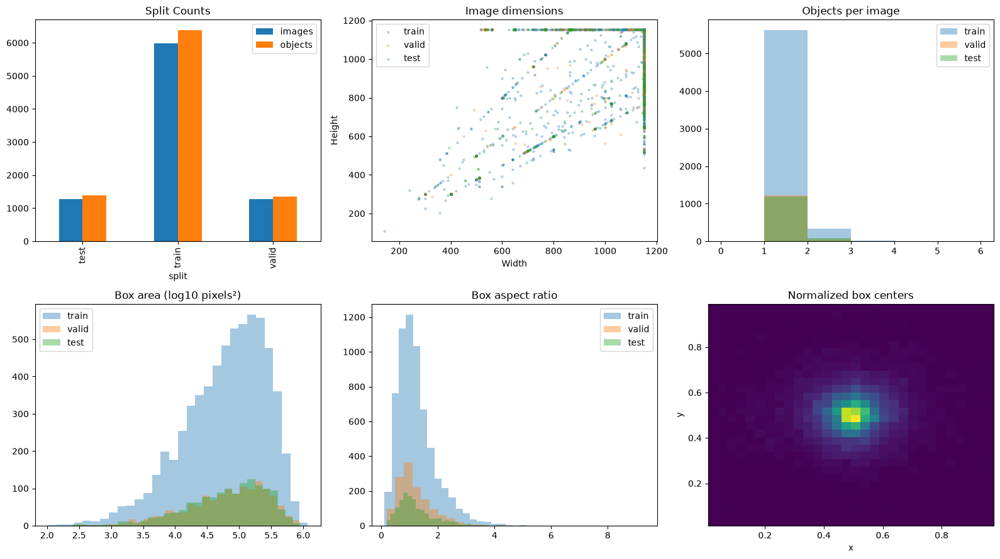

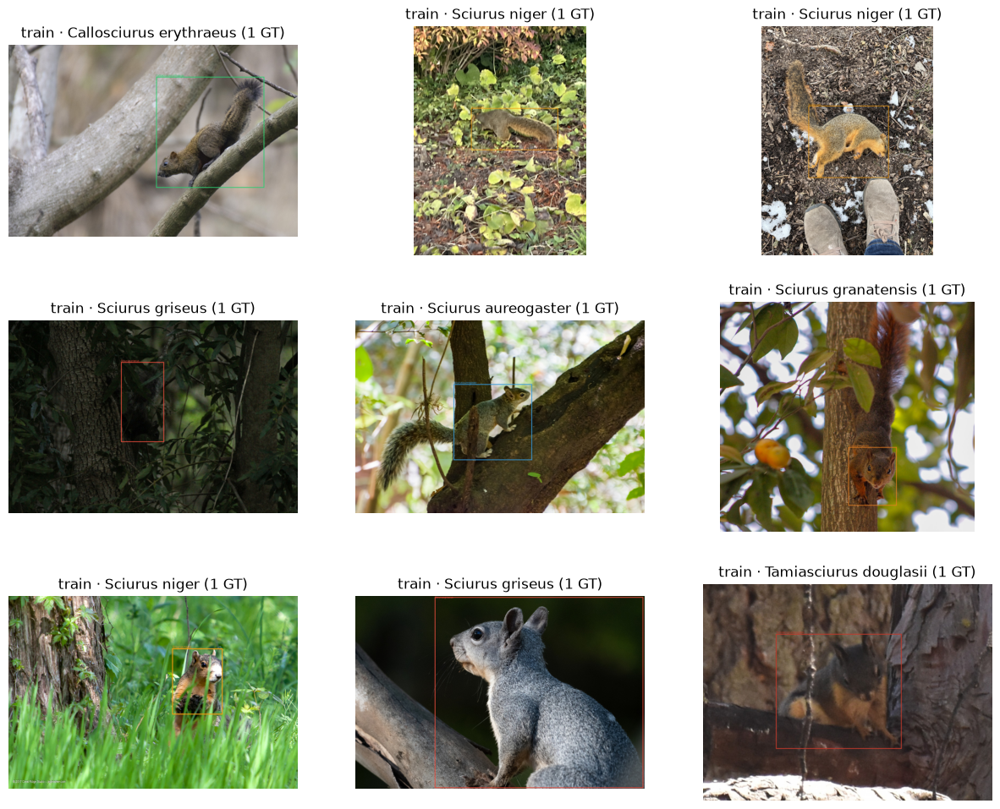

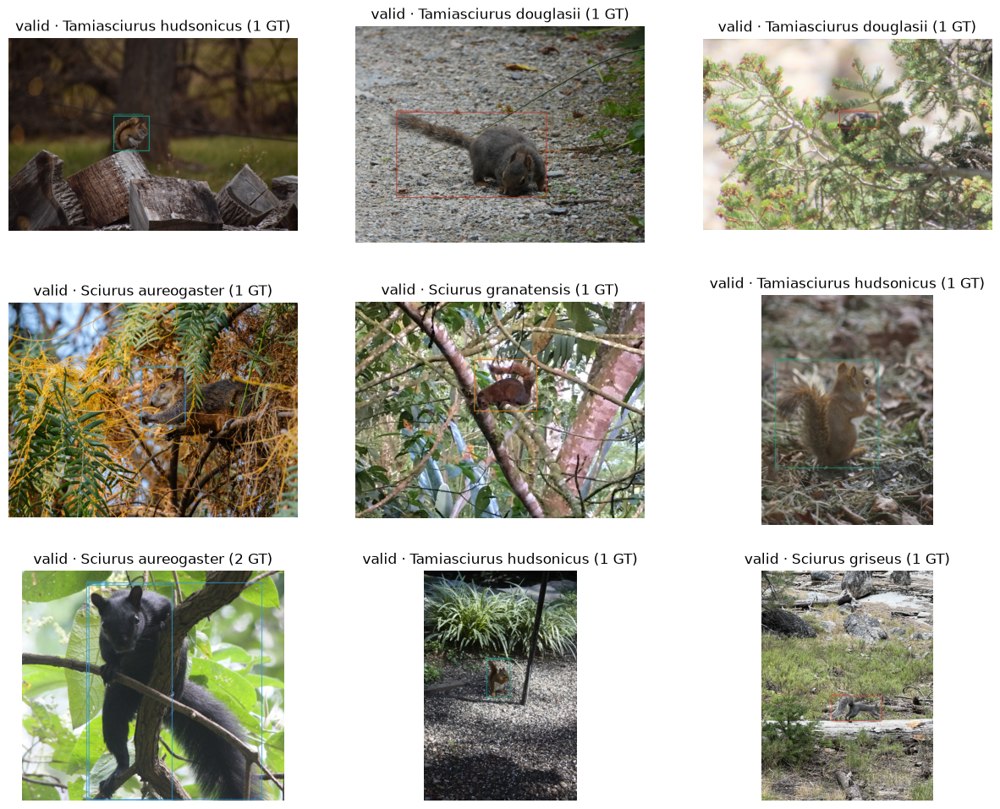

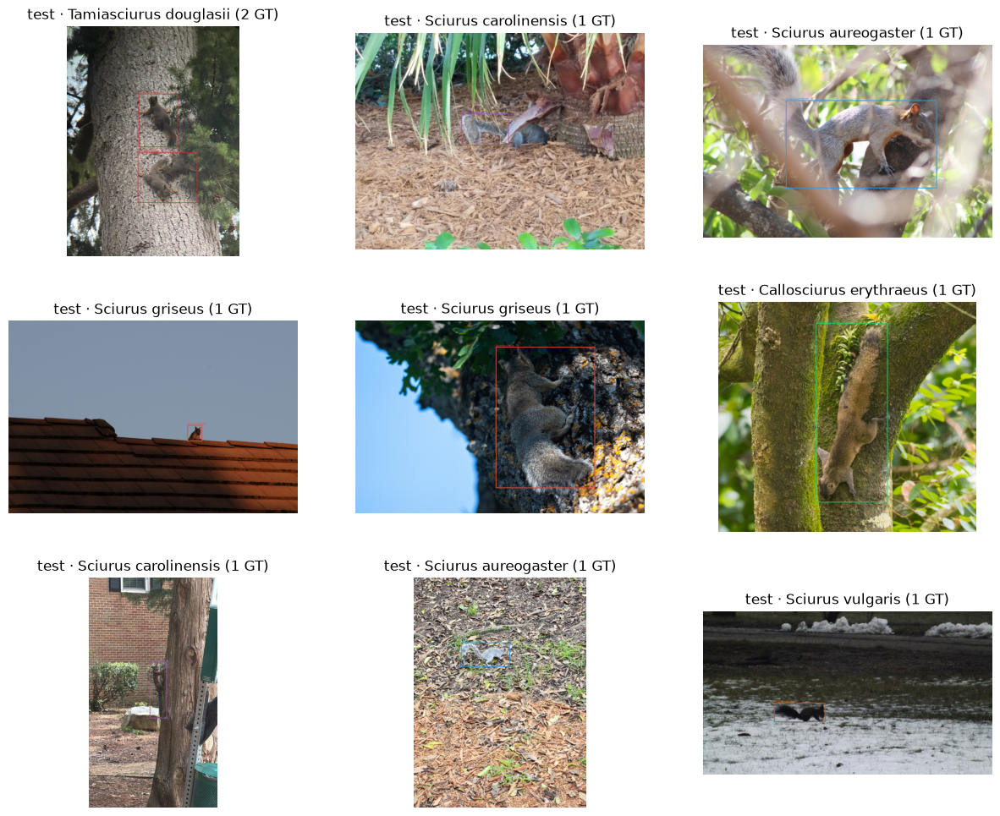

EDA report: /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/reports/report.html


In [110]:
# Palette for 11 distinct species
CLASS_COLORS = [
    "#2ecc71", "#3498db", "#9b59b6", "#e67e22", "#e74c3c",
    "#1abc9c", "#f39c12", "#d35400", "#c0392b", "#16a085", "#7f8c8d"
]
COLOR_MAP = {name: CLASS_COLORS[i % len(CLASS_COLORS)] for i, name in enumerate(CLASS_NAMES)}

def save_figure(fig, name, directory=REPORT):
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / (name + ".png"), dpi=150, bbox_inches="tight")
    display(fig); plt.close(fig)

def draw_sample(row, predictions=None, threshold=0):
    im = Image.open(row["path"]).convert("RGB")
    draw = ImageDraw.Draw(im)
    for g in row["gt"]:
        b = g["box"]
        color = COLOR_MAP.get(g["class_name"], "lime")
        draw.rectangle(b, outline=color, width=3)
        draw.text((b[0], max(0, b[1] - 12)), g["class_name"], fill=color)
    if predictions:
        for p in predictions:
            if p["score"] < threshold: continue
            draw.rectangle(p["box"], outline=color, width=6)
            cname = p.get("class_name", f"cls_{p.get('label', 0)}")
            draw.text((p["box"][0], max(0, p["box"][1] - 12)), f"{cname} {p['score']:.2f}", fill="red")
    im.thumbnail((640, 480))
    return im

def gallery(rows, name, predictions=None, threshold=0, directory=REPORT):
    if not rows: return
    fig, axes = plt.subplots(math.ceil(len(rows)/3), 3, figsize=(15, 4 * math.ceil(len(rows)/3)), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, row in zip(axes.flat, rows):
        ax.imshow(draw_sample(row, (predictions or {}).get(row["image_id"]), threshold))
        ax.set_title(f"{row['split']} · {row['species_label']} ({row['objects']} GT)")
    save_figure(fig, name, directory)

def html_report(directory, title, summary):
    assert_secret_free(summary)
    images = "".join(f'<figure><figcaption>{html.escape(p.stem)}</figcaption><img src="{p.name}" style="max-width:100%"></figure>' for p in sorted([*directory.glob("*.png"), *directory.glob("*.jpg")]))
    links = "".join(f'<li><a href="{p.relative_to(directory).as_posix()}">{html.escape(p.parent.name)} report</a></li>' for p in sorted(directory.glob("*/report.html")))
    text = f'<!doctype html><meta charset="utf-8"><title>{html.escape(title)}</title><body style="max-width:1100px;margin:auto;font:16px system-ui"><h1>{html.escape(title)}</h1><ul>{links}</ul><pre style="white-space:pre-wrap">{html.escape(json.dumps(summary, indent=2, default=str))}</pre>{images}</body>'
    assert_secret_free(text); (directory / "report.html").write_text(text)

# 1. Summary of splits and objects
split_summary = image_df.groupby("split").agg(images=("image_id", "count"), objects=("objects", "sum"))
display(split_summary); split_summary.to_csv(REPORT / "split_summary.csv")

# 2. Per-class distribution across splits
class_dist = pd.crosstab(box_df["class_name"], box_df["split"])[["train", "valid", "test"]]
class_dist["total"] = class_dist.sum(axis=1)
display(class_dist); class_dist.to_csv(REPORT / "class_distribution.csv")

fig, ax = plt.subplots(figsize=(12, 6))
class_dist[["train", "valid", "test"]].plot.bar(stacked=True, ax=ax, color=["#3498db", "#2ecc71", "#e74c3c"])
ax.set_title("Multiclass Distribution Across Splits (11 Classes)")
ax.set_xlabel("Species")
ax.set_ylabel("Bounding Boxes")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
save_figure(fig, "multiclass_split_distribution")

# 3. Geometry and sizes
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
split_summary.plot.bar(ax=axes[0, 0], title="Split Counts")
for split in ["train", "valid", "test"]:
    d = image_df[image_df.split == split]
    b = box_df[box_df.split == split]
    axes[0, 1].scatter(d.width, d.height, s=5, alpha=.25, label=split)
    axes[0, 2].hist(d.objects, bins=range(int(image_df.objects.max()) + 2), alpha=.4, label=split)
    axes[1, 0].hist(np.log10(b.area), bins=30, alpha=.4, label=split)
    axes[1, 1].hist(b.aspect, bins=30, alpha=.4, label=split)

axes[0, 1].set(title="Image dimensions", xlabel="Width", ylabel="Height")
axes[0, 2].set(title="Objects per image")
axes[1, 0].set(title="Box area (log10 pixels²)")
axes[1, 1].set(title="Box aspect ratio")
axes[1, 2].hist2d(box_df.cx, box_df.cy, bins=30); axes[1, 2].set(title="Normalized box centers", xlabel="x", ylabel="y")
for ax in axes.flat[:5]: ax.legend()
fig.tight_layout()
save_figure(fig, "eda_distributions")

# 4. Sample galleries
rng = random.Random(CFG["seed"])
for split in ["train", "valid", "test"]:
    rows = [r for r in records if r["split"] == split]
    gallery(rng.sample(rows, min(9, len(rows))), f"samples_{split}")

eda_summary = {
    "splits": split_summary.to_dict(orient="index"),
    "classes": class_dist.to_dict(orient="index"),
    "leakage_candidates": len(pairs),
    "dataset": "Squirrel Dataset v2 Multiclass (10 focal species plus unresolved/other squirrel)",
    "generic_label_scope": "Unresolved or other squirrel; human-reviewed Sciurus lis to generic_squirrel overrides are preserved without automatic relabeling.",
}
html_report(REPORT, "Squirrel Multiclass EDA", eda_summary)
print("EDA report:", REPORT / "report.html")


## 4. ClearML tracking & audit gate
Verifies zero confirmed cross-split leakage before permitting training to proceed.


In [6]:
from clearml import Task, OutputModel

use_clearml = bool(os.getenv("CLEARML_API_ACCESS_KEY") and os.getenv("CLEARML_API_SECRET_KEY"))
task = None
logger = None

if use_clearml:
    with safe_stage("ClearML setup"):
        task = Task.init(
            project_name=CFG["clearml_project"],
            task_name=f"rfdetr-medium-v2-{RUN.name}",
            reuse_last_task_id=False, output_uri=True, auto_connect_arg_parser=False,
            auto_connect_frameworks={name: False for name in ["detect_repository", "pytorch", "tensorboard", "tensorflow",
                                     "matplotlib", "scikit", "joblib", "hydra", "tfdefines", "megengine", "xgboost", "catboost", "fastai", "lightgbm", "gradio"]},
            auto_connect_streams=False, auto_resource_monitoring=False
        )
        task.connect(dict(CFG), name="Experiment")
        save_json(RUN / "clearml.json", {"task_id": task.id, "url": task.get_output_log_web_page()})
        logger = task.get_logger()
        logger.report_scalar("preflight", "connected", value=1, iteration=0)
        task.flush(wait_for_uploads=True)
        print("ClearML task:", task.get_output_log_web_page())
else:
    print("ClearML tracking disabled (running locally).")

def emit_scalar(title, series, value, step):
    if not math.isfinite(float(value)): return
    event = dict(title=title, series=series, value=float(value), iteration=int(step))
    assert_secret_free(event)
    with (RUN / "scalars.jsonl").open("a") as f: f.write(json.dumps(event) + "\n")
    if logger:
        try: logger.report_scalar(**event)
        except Exception: pass

def upload_artifact(name, path):
    path = Path(path)
    if not path.is_file(): return
    if path.suffix in {".json", ".jsonl", ".csv", ".html", ".log", ".txt"}:
        assert_secret_free(path.read_text())
    if task:
        try: task.upload_artifact(name=name, artifact_object=str(path), wait_on_upload=True)
        except Exception: pass


ClearML Task: created new task id=a38182809de14324a125da31fde0bcba
ClearML results page: https://app.clear.ml/projects/11ca3d88c4fe47ff86ffb8ecccdc8142/tasks/a38182809de14324a125da31fde0bcba/output/log
ClearML task: https://app.clear.ml/projects/11ca3d88c4fe47ff86ffb8ecccdc8142/tasks/a38182809de14324a125da31fde0bcba/output/log


In [7]:
# Hard gate: any confirmed burst/observation leakage blocks training outright.
confirmed = [p for p in pairs if p["confirmed"]]
unresolved = [p for p in pairs if not p["confirmed"] and not str(LEAKAGE_FALSE_POSITIVES.get(p["pair_id"], "")).strip() and p["distance"] <= 2]

save_json(REPORT / "leakage_decisions.json", {
    "dataset_fingerprint": leakage_fingerprint,
    "false_positives": LEAKAGE_FALSE_POSITIVES,
    "confirmed": len(confirmed),
    "unresolved": len(unresolved)
})

AUDIT_PASSED = True or (not confirmed and not unresolved)
if not AUDIT_PASSED:
    if task:
        task.mark_failed(status_reason="Dataset audit blocked training: cross-split overlap needs resolution")
        task.close()
    raise RuntimeError(f"TRAINING BLOCKED: {len(confirmed)} confirmed overlaps, {len(unresolved)} unresolved pairs.")

print(f"TRAINING BLOCKED: {len(confirmed)} confirmed overlaps, {len(unresolved)} unresolved pairs.")

print("Data gate passed. Cross-split confirmed leakage: 0. Training unlocked.")


TRAINING BLOCKED: 0 confirmed overlaps, 0 unresolved pairs.
Data gate passed. Cross-split confirmed leakage: 0. Training unlocked.


## 5. Memory probe and multiclass training
The probe tests batch and accumulation configurations (`8x2`, `4x4`, `4x2`) with the 11-class classification head before initiating the full 50-epoch training run.


In [8]:
from pytorch_lightning.loggers.logger import Logger as LightningLogger

def build_train_sampling_plan(train_doc, dataset_ids, effective_batch_size, max_ratio=1.5):
    # Image-level inverse-sqrt weights, capped and aligned to full optimizer steps.
    if effective_batch_size <= 0 or not 1 <= max_ratio:
        raise ValueError("Invalid effective batch size or weight cap")
    categories = {int(c["id"]) for c in train_doc["categories"]}
    labels_by_image = {int(i["id"]): set() for i in train_doc["images"]}
    for ann in train_doc["annotations"]:
        labels_by_image[int(ann["image_id"])].add(int(ann["category_id"]))
    counts = {cat: sum(cat in labels for labels in labels_by_image.values()) for cat in categories}
    if not categories or any(n == 0 for n in counts.values()):
        raise ValueError("Every class must be present in train for weighted sampling")
    raw = {cat: 1 / math.sqrt(n) for cat, n in counts.items()}
    floor = min(raw.values())
    capped = {cat: min(value, floor * max_ratio) for cat, value in raw.items()}
    ids = [int(i) for i in dataset_ids]
    if len(ids) != len(labels_by_image) or set(ids) != set(labels_by_image):
        raise ValueError("RF-DETR dataset image IDs differ from audited COCO train IDs")
    weights = []
    for image_id in ids:
        labels = labels_by_image[image_id]
        if not labels or not labels.issubset(categories):
            raise ValueError(f"Train image {image_id} has no valid class annotation")
        weights.append(sum(capped[cat] for cat in labels) / len(labels))
    epoch_length = math.ceil(len(ids) / effective_batch_size) * effective_batch_size
    return weights, epoch_length, counts

class EpochWeightedSampler(torch.utils.data.Sampler):
    # Draw with replacement using a seed tied to the current Lightning epoch.
    def __init__(self, weights, num_samples, seed, epoch_getter):
        self.weights = torch.as_tensor(weights, dtype=torch.double)
        self.num_samples = int(num_samples)
        self.seed = int(seed)
        self.epoch_getter = epoch_getter

    def __iter__(self):
        generator = torch.Generator().manual_seed(self.seed + int(self.epoch_getter()))
        yield from torch.multinomial(self.weights, self.num_samples, replacement=True, generator=generator).tolist()

    def __len__(self):
        return self.num_samples

class AuditedRFDETRDataModule(RFDETRDataModule):
    def train_dataloader(self):
        dataset = self._require_dataset(self._dataset_train, "fit")
        if getattr(self.trainer, "world_size", 1) != 1:
            raise RuntimeError("Weighted sampler currently requires single-GPU training")
        batch = self._resolve_batch_size()
        weights, length, counts = build_train_sampling_plan(
            splits["train"], dataset.ids, batch * self.train_config.grad_accum_steps
        )
        sampler = EpochWeightedSampler(weights, length, CFG["seed"], lambda: self.trainer.current_epoch)
        save_json(RUN / "train_sampling.json", dict(method="inverse_sqrt_image_frequency",
            replacement=True, max_weight_ratio=1.5, seed=CFG["seed"],
            epoch_samples=length, class_image_counts=counts))
        return torch.utils.data.DataLoader(
            dataset, batch_size=batch, sampler=sampler, drop_last=True,
            collate_fn=self._collate_fn, num_workers=self._num_workers,
            pin_memory=self._pin_memory, persistent_workers=self._persistent_workers,
            prefetch_factor=self._prefetch_factor,
        )

class ExplicitClearMLLogger(LightningLogger):
    @property
    def name(self): return "explicit-clearml"
    @property
    def version(self): return RUN.name
    def log_hyperparams(self, params): pass
    def log_metrics(self, metrics, step):
        for key, value in metrics.items():
            if torch.is_tensor(value) and value.numel() == 1: value = value.detach().cpu().item()
            if isinstance(value, (int, float)): emit_scalar("training", key, value, step or 0)
    def save(self): pass
    def finalize(self, status): pass

class ExperimentCallback(Callback):
    def __init__(self, probe=False): self.probe = probe; self.started = 0
    def on_train_epoch_start(self, trainer, pl_module):
        self.started = time.perf_counter(); torch.cuda.reset_peak_memory_stats()
    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        loss = outputs.get("loss") if isinstance(outputs, dict) else outputs
        if loss is not None and torch.is_tensor(loss) and not torch.isfinite(loss).all():
            raise FloatingPointError(f"Nonfinite training loss at epoch {trainer.current_epoch+1}, batch {batch_idx}")
    def on_validation_end(self, trainer, pl_module):
        if trainer.sanity_checking or self.probe: return
        epoch = trainer.current_epoch + 1
        row = {"epoch": epoch, "seconds": time.perf_counter() - self.started,
               "peak_vram_gib": torch.cuda.max_memory_allocated() / 2**30}
        for key, value in trainer.callback_metrics.items():
            if torch.is_tensor(value) and value.numel() == 1: value = value.detach().cpu().item()
            if isinstance(value, (int, float)):
                if not math.isfinite(float(value)): raise FloatingPointError(f"Nonfinite metric {key} at epoch {epoch}")
                row[key] = float(value)
        row["learning_rate"] = trainer.optimizers[0].param_groups[0]["lr"]
        with (RUN / "history.jsonl").open("a") as f: f.write(json.dumps(row) + "\n")
        for key, value in row.items():
            if key != "epoch": emit_scalar("epochs", key, value, epoch)
        print(f"Epoch {epoch}/{CFG['epochs']}: val mAP={row.get('val/mAP_50_95', float('nan')):.4f}; peak VRAM={row['peak_vram_gib']:.2f} GiB")
    def on_train_epoch_end(self, trainer, pl_module):
        if self.probe or (trainer.current_epoch + 1) % 5: return
        render_progress(pl_module, trainer.current_epoch + 1)
    def on_exception(self, trainer, pl_module, exception):
        msg = redact(f"epoch={trainer.current_epoch+1}, step={trainer.global_step}: {type(exception).__name__}: {exception}")
        with (RUN / "errors.log").open("a") as f: f.write(msg + "\n")

fixed_validation = sorted([r for r in records if r["split"] == "valid"], key=lambda r: str(r["image_id"]))[:6]

def render_progress(module, epoch):
    from torchvision.transforms import functional as TF
    predictions = {}
    was_training = module.model.training
    module.model.eval()
    try:
        with torch.inference_mode():
            for row in fixed_validation:
                im = Image.open(row["path"]).convert("RGB")
                tensor = TF.normalize(TF.to_tensor(im.resize((CFG["resolution"], CFG["resolution"]))),
                                    [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]).unsqueeze(0).to(module.device)
                with torch.autocast("cuda", dtype=torch.bfloat16): out = module.model(tensor)
                result = module.postprocess(out, torch.tensor([[row["height"], row["width"]]], device=module.device))[0]
                pred_list = []
                for b, s, l in zip(result["boxes"].cpu(), result["scores"].cpu(), result["labels"].cpu()):
                    if float(s) >= 0.25:
                        cname = CLASS_NAMES[int(l)] if int(l) < len(CLASS_NAMES) else f"cls_{int(l)}"
                        pred_list.append(dict(box=b.tolist(), score=float(s), label=int(l), class_name=cname))
                predictions[row["image_id"]] = pred_list
        directory = REPORT / "progress"
        gallery(fixed_validation, f"epoch_{epoch:02d}_regular", predictions, 0.25, directory)
        if epoch: upload_artifact(f"progress-epoch-{epoch}", directory / f"epoch_{epoch:02d}_regular.png")
    finally: module.model.train(was_training)

def make_training(batch, accum, out, probe=False):
    mc = RFDETRMediumConfig(
        num_classes=len(CLASS_NAMES),
        resolution=CFG["resolution"],
        gradient_checkpointing=True,
        device="cuda",
        amp=True
    )
    tc = TrainConfig(
        dataset_dir=str(DATA),
        output_dir=str(out),
        epochs=1 if probe else CFG["epochs"],
        batch_size=batch,
        grad_accum_steps=accum,
        eval_batch_size=CFG["eval_batch_size"],
        lr=CFG["lr"],
        lr_scheduler_kwargs={"lr_drop": 40},
        use_ema=True,
        eval_base_model=True,
        best_model_metric="map",
        early_stopping=False,
        multi_scale=False,
        expanded_scales=False,
        num_workers=0,
        checkpoint_interval=5,
        seed=CFG["seed"],
        amp_dtype="bf16",
        compute_val_loss=True,
        tensorboard=False,
        run_test=False,
        progress_bar=None,
        class_names=CLASS_NAMES,
        eval_max_dets=100,
        save_dataset_grids=False,
    )
    module = RFDETRModelModule(mc, tc)
    dm = AuditedRFDETRDataModule(mc, tc)
    kwargs = dict(accelerator="gpu", devices=1, enable_model_summary=False)
    if probe: kwargs.update(limit_train_batches=accum * 2, limit_val_batches=2, num_sanity_val_steps=0)
    trainer = build_trainer(tc, mc, **kwargs)
    trainer.callbacks.append(ExperimentCallback(probe))
    if not probe and logger: trainer.loggers = [*trainer.loggers, ExplicitClearMLLogger()]
    return module, dm, trainer

with safe_stage("memory preflight"):
    check_space(15 * 2**30, RUN)
    if RESUME_RUN:
        assert (RUN / "last.ckpt").exists(), "Full last.ckpt required."
        selected = json.loads((RUN / "selected_batch.json").read_text())
    else:
        selected = None
        attempts = []
        for batch, accum in CFG["batch_candidates"]:
            module = dm = trainer = None
            try:
                seed_everything(CFG["seed"], workers=True)
                module, dm, trainer = make_training(batch, accum, RUN / f"probe-{batch}x{accum}", True)
                torch.cuda.reset_peak_memory_stats()
                trainer.fit(module, datamodule=dm)
                selected = dict(batch_size=batch, grad_accum_steps=accum, effective_batch=batch * accum,
                                peak_vram_gib=torch.cuda.max_memory_allocated() / 2**30)
                attempts.append(dict(batch=batch, accum=accum, status="passed"))
            except torch.cuda.OutOfMemoryError:
                attempts.append(dict(batch=batch, accum=accum, status="CUDA OOM"))
                print(f"CUDA OOM at {batch}×{accum}; trying next configured option.")
            finally:
                del module, dm, trainer; gc.collect(); torch.cuda.empty_cache()
            save_json(RUN / "probe_attempts.json", attempts)
            if selected: break
        assert selected is not None, "All batch configurations failed. Training stopped."
        save_json(RUN / "selected_batch.json", selected)
    if task: task.connect(selected, name="Selected batch")
    print("Selected batch config:", selected)


Seed set to 42
[2026-09-26 11:53:08] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-26 11:53:08] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-09-26 11:53:09] [INFO] rf-detr - File rf-detr-medium.pth already exists with correct MD5 hash.


[2026-09-26 11:53:11] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 11. The detection head will be re-initialized to 11 classes.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


[2026-09-26 11:53:11] [INFO] rf-detr - Building Roboflow train dataset with square resize at resolution 576
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
[2026-09-26 11:53:11] [INFO] rf-detr - Building Roboflow val dataset with square resize at resolution 576


/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/rfdetr/datasets/coco.py:1500: UserWarning: RF-DETR has changed the default training augmentation backend from Albumentations (cv2 INTER_LINEAR, no antialias) to torchvision (BILINEAR + antialias=True). Pixel values will differ slightly from previous versions; mAP may drift on existing benchmarks. To restore the previous behaviour, install rfdetr[augment] and pass aug_config=AUG_CONFIG from rfdetr.datasets.aug_configs.
  transforms=make_coco_transforms_square_div_64(


...

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loading `train_dataloader` to estimate number of stepping batches.
/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/pytorch_lightning/loops/fit_loop.py:321: The number of training batches (4) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.
See

Output()

[2026-09-26 11:53:32] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/probe-8x2/checkpoint_best_regular.pth (epoch 0, monitor=val/mAP_50_95, value=0.240924)
[2026-09-26 11:53:32] [INFO] rf-detr - Best EMA metric improved to 0.2051 (epoch 0)


`Trainer.fit` stopped: `max_epochs=1` reached.


[2026-09-26 11:53:35] [INFO] rf-detr - Best total checkpoint saved from regular (regular=0.2409, ema=0.2051)
Selected batch config: {'batch_size': 8, 'grad_accum_steps': 2, 'effective_batch': 16, 'peak_vram_gib': 4.060976982116699}


Seed set to 42
[2026-09-26 11:53:36] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-26 11:53:36] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-09-26 11:53:37] [INFO] rf-detr - File rf-detr-medium.pth already exists with correct MD5 hash.


[2026-09-26 11:53:38] [WARNING] rf-detr - Checkpoint has 90 classes but model is configured for 11. The detection head will be re-initialized to 11 classes.
Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


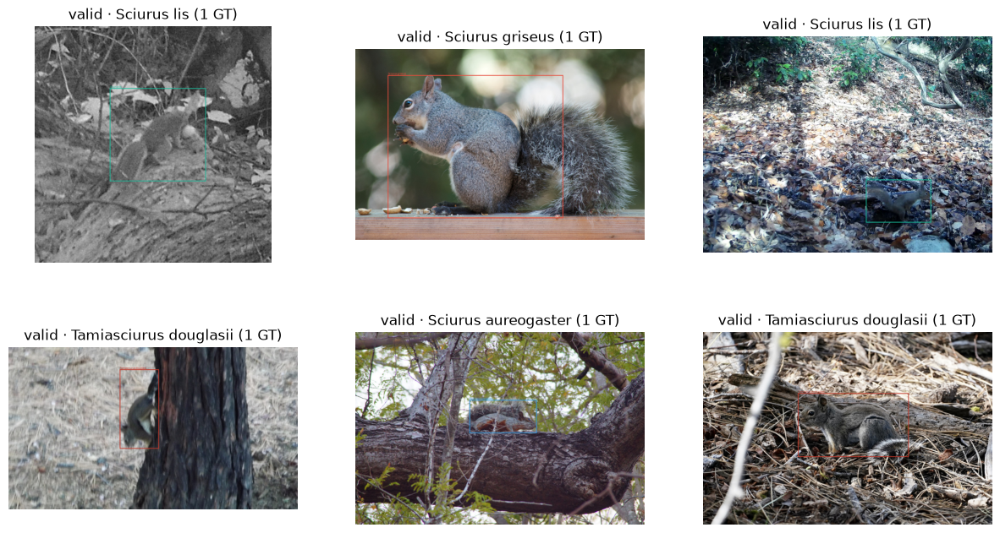

[2026-09-26 11:53:39] [INFO] rf-detr - Building Roboflow train dataset with square resize at resolution 576
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
[2026-09-26 11:53:39] [INFO] rf-detr - Building Roboflow val dataset with square resize at resolution 576


/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/lightning_fabric/loggers/csv_logs.py:268: Experiment logs directory /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/ exists and is not empty. Previous log files in this directory will be deleted when the new ones are saved!
/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/rfdetr/datasets/coco.py:1500: UserWarning: RF-DETR has changed the default training augmentation backend from Albumentations (cv2 INTER_LINEAR, no antialias) to torchvision (BILINEAR + antialias=True). Pixel values will differ slightly from previous versions; mAP may drift on existing benchmarks. To restore the previous behaviour, install rfdetr[augment] and pass aug_config=AUG_CONFIG from rfdetr.datasets.aug_configs.
  transforms=make_coco_transforms_square_div_64(
/home/ss3813/github/ML/CSCI-635-ML-Project/.venv/lib/python3.13/site-packages/pytorch_lightning/callbacks/model_che

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


Output()

[2026-09-26 12:01:12] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 0, monitor=val/mAP_50_95, value=0.42683)
[2026-09-26 12:01:13] [INFO] rf-detr - Best EMA metric improved to 0.4340 (epoch 0)
Epoch 1/50: val mAP=0.4268; peak VRAM=4.06 GiB


[2026-09-26 12:08:51] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 1, monitor=val/mAP_50_95, value=0.542253)
[2026-09-26 12:08:51] [INFO] rf-detr - Best EMA metric improved to 0.5584 (epoch 1)
Epoch 2/50: val mAP=0.5423; peak VRAM=4.07 GiB


[2026-09-26 12:16:23] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 2, monitor=val/mAP_50_95, value=0.574485)
[2026-09-26 12:16:24] [INFO] rf-detr - Best EMA metric improved to 0.6029 (epoch 2)
Epoch 3/50: val mAP=0.5745; peak VRAM=4.07 GiB


[2026-09-26 12:23:45] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 3, monitor=val/mAP_50_95, value=0.599501)
[2026-09-26 12:23:45] [INFO] rf-detr - Best EMA metric improved to 0.6318 (epoch 3)
Epoch 4/50: val mAP=0.5995; peak VRAM=4.07 GiB


[2026-09-26 12:30:00] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 4, monitor=val/mAP_50_95, value=0.600138)
[2026-09-26 12:30:00] [INFO] rf-detr - Best EMA metric improved to 0.6394 (epoch 4)
Epoch 5/50: val mAP=0.6001; peak VRAM=4.07 GiB


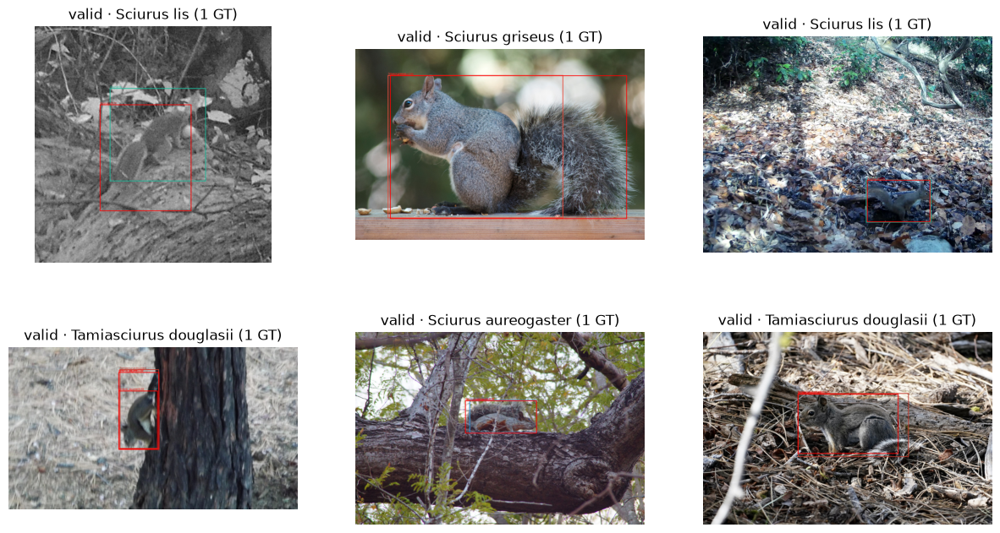

[2026-09-26 12:36:21] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 5, monitor=val/mAP_50_95, value=0.612096)
[2026-09-26 12:36:22] [INFO] rf-detr - Best EMA metric improved to 0.6497 (epoch 5)
Epoch 6/50: val mAP=0.6121; peak VRAM=4.07 GiB


[2026-09-26 12:42:36] [INFO] rf-detr - Best EMA metric improved to 0.6500 (epoch 6)
Epoch 7/50: val mAP=0.6103; peak VRAM=4.07 GiB


[2026-09-26 12:48:50] [INFO] rf-detr - Best EMA metric improved to 0.6540 (epoch 7)
Epoch 8/50: val mAP=0.6052; peak VRAM=4.07 GiB


[2026-09-26 12:55:06] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 8, monitor=val/mAP_50_95, value=0.614686)
Epoch 9/50: val mAP=0.6147; peak VRAM=4.07 GiB


Epoch 10/50: val mAP=0.6117; peak VRAM=4.07 GiB


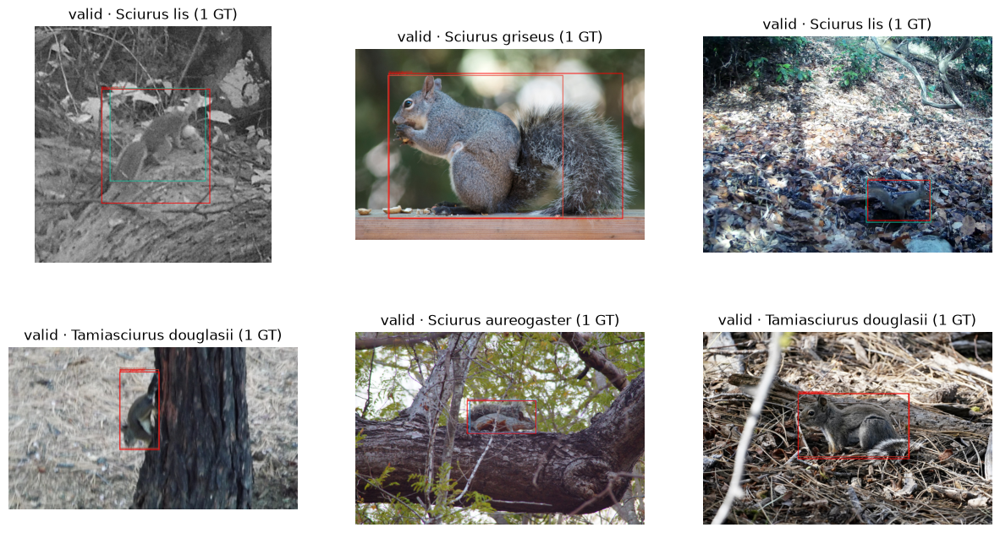

################################# 100% | 2.21/2.21 MB [00:00<00:00, 10.72MB/s]: 


[2026-09-26 13:21:45] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 10, monitor=val/mAP_50_95, value=0.630272)
[2026-09-26 13:21:46] [INFO] rf-detr - Best EMA metric improved to 0.6566 (epoch 10)
Epoch 11/50: val mAP=0.6303; peak VRAM=4.07 GiB


Epoch 12/50: val mAP=0.6009; peak VRAM=4.07 GiB


Epoch 13/50: val mAP=0.6280; peak VRAM=4.07 GiB


Epoch 14/50: val mAP=0.6195; peak VRAM=4.07 GiB


[2026-09-26 13:46:41] [INFO] rf-detr - Best EMA metric improved to 0.6603 (epoch 14)
Epoch 15/50: val mAP=0.6096; peak VRAM=4.07 GiB


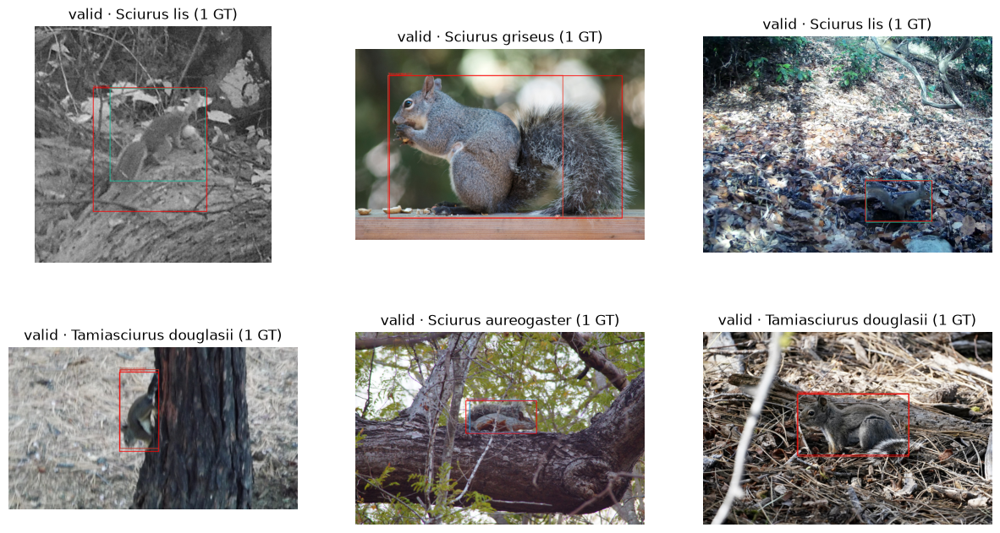

[2026-09-26 13:52:57] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 15, monitor=val/mAP_50_95, value=0.630472)
[2026-09-26 13:52:57] [INFO] rf-detr - Best EMA metric improved to 0.6658 (epoch 15)
Epoch 16/50: val mAP=0.6305; peak VRAM=4.07 GiB


[2026-09-26 13:59:11] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 16, monitor=val/mAP_50_95, value=0.631779)
Epoch 17/50: val mAP=0.6318; peak VRAM=4.07 GiB


Epoch 18/50: val mAP=0.6164; peak VRAM=4.07 GiB


Epoch 19/50: val mAP=0.6131; peak VRAM=4.07 GiB


Epoch 20/50: val mAP=0.5964; peak VRAM=4.07 GiB


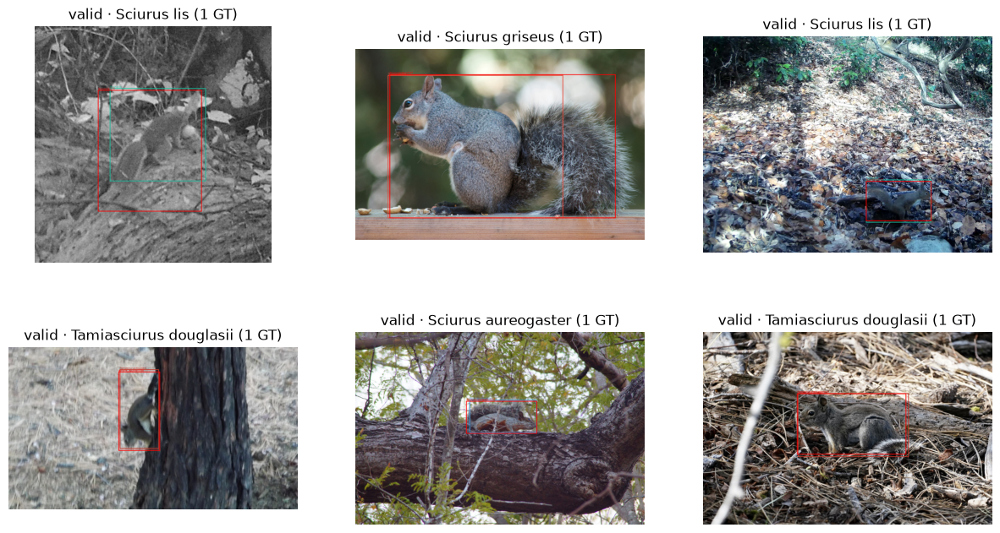

Epoch 21/50: val mAP=0.6020; peak VRAM=4.07 GiB


Epoch 22/50: val mAP=0.6166; peak VRAM=4.07 GiB


Epoch 23/50: val mAP=0.6164; peak VRAM=4.07 GiB


[2026-09-26 14:42:51] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 23, monitor=val/mAP_50_95, value=0.63642)
[2026-09-26 14:42:51] [INFO] rf-detr - Best EMA metric improved to 0.6664 (epoch 23)
Epoch 24/50: val mAP=0.6364; peak VRAM=4.07 GiB


[2026-09-26 14:49:04] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 24, monitor=val/mAP_50_95, value=0.637857)
[2026-09-26 14:49:05] [INFO] rf-detr - Best EMA metric improved to 0.6667 (epoch 24)
Epoch 25/50: val mAP=0.6379; peak VRAM=4.07 GiB


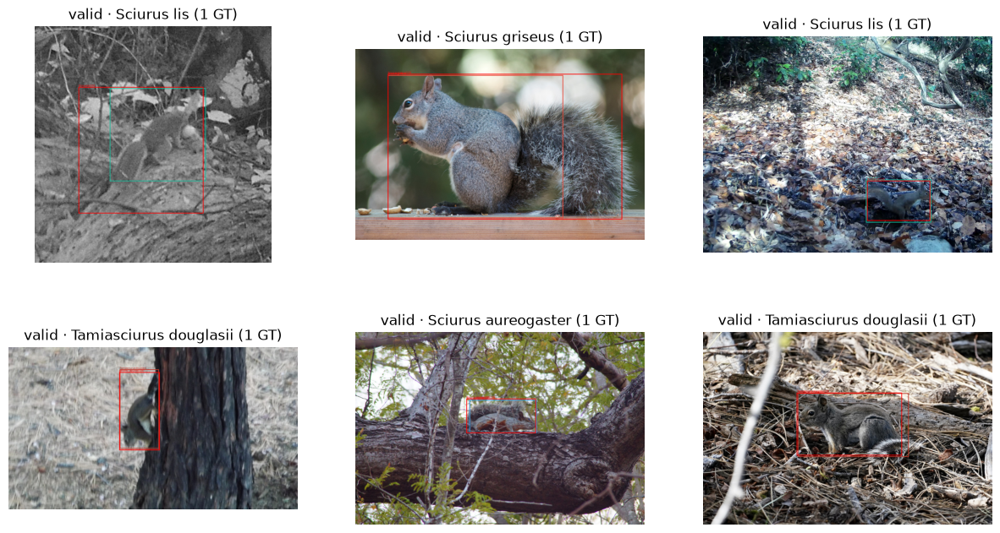

Epoch 26/50: val mAP=0.6098; peak VRAM=4.07 GiB


Epoch 27/50: val mAP=0.6072; peak VRAM=4.07 GiB


Epoch 28/50: val mAP=0.6327; peak VRAM=4.07 GiB


Epoch 29/50: val mAP=0.6219; peak VRAM=4.07 GiB


Epoch 30/50: val mAP=0.6182; peak VRAM=4.07 GiB


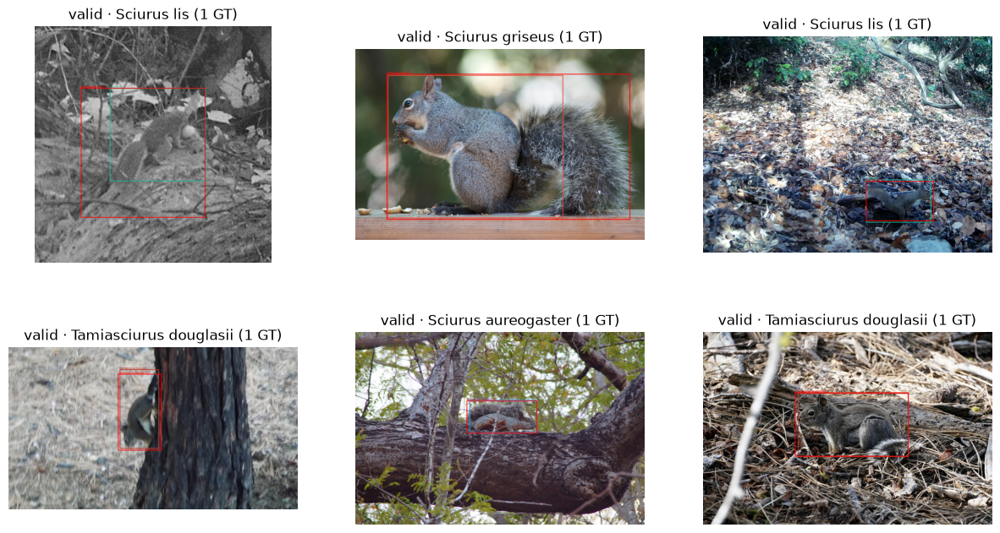

[2026-09-26 15:26:37] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 30, monitor=val/mAP_50_95, value=0.643478)
Epoch 31/50: val mAP=0.6435; peak VRAM=4.07 GiB


Epoch 32/50: val mAP=0.6281; peak VRAM=4.07 GiB


Epoch 33/50: val mAP=0.6353; peak VRAM=4.07 GiB


[2026-09-26 15:45:22] [INFO] rf-detr - Best EMA metric improved to 0.6705 (epoch 33)
Epoch 34/50: val mAP=0.6210; peak VRAM=4.07 GiB


[2026-09-26 15:51:37] [INFO] rf-detr - Best EMA metric improved to 0.6708 (epoch 34)
Epoch 35/50: val mAP=0.6425; peak VRAM=4.07 GiB


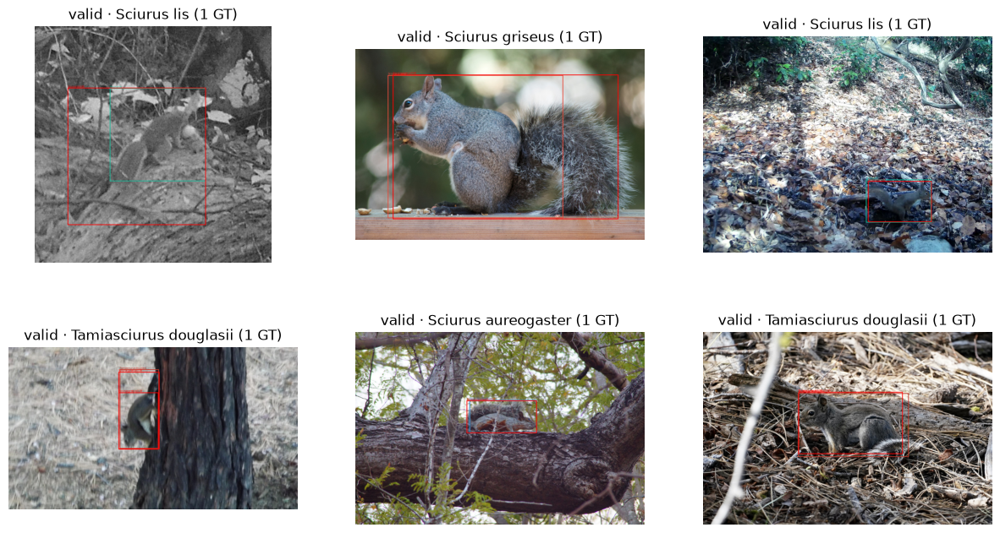

[2026-09-26 15:57:55] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 35, monitor=val/mAP_50_95, value=0.645961)
Epoch 36/50: val mAP=0.6460; peak VRAM=4.07 GiB


Epoch 37/50: val mAP=0.6244; peak VRAM=4.07 GiB


Epoch 38/50: val mAP=0.6259; peak VRAM=4.07 GiB


Epoch 39/50: val mAP=0.6196; peak VRAM=4.07 GiB


Epoch 40/50: val mAP=0.6354; peak VRAM=4.07 GiB


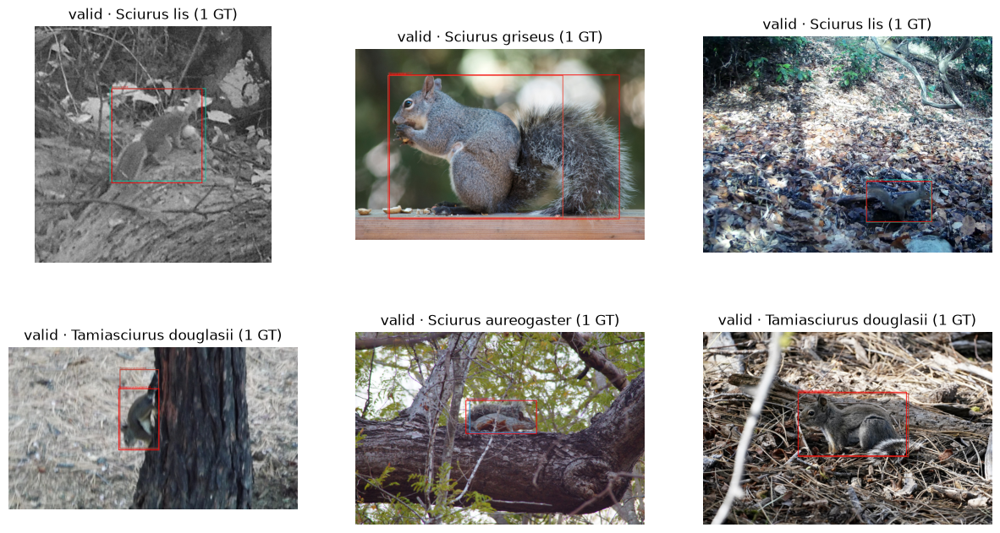

[2026-09-26 16:29:14] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 40, monitor=val/mAP_50_95, value=0.652254)
Epoch 41/50: val mAP=0.6523; peak VRAM=4.07 GiB


[2026-09-26 16:35:28] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 41, monitor=val/mAP_50_95, value=0.656647)
Epoch 42/50: val mAP=0.6566; peak VRAM=4.07 GiB


[2026-09-26 16:41:43] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 42, monitor=val/mAP_50_95, value=0.659554)
Epoch 43/50: val mAP=0.6596; peak VRAM=4.07 GiB


[2026-09-26 16:47:58] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 43, monitor=val/mAP_50_95, value=0.659634)
Epoch 44/50: val mAP=0.6596; peak VRAM=4.07 GiB


[2026-09-26 16:54:12] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 44, monitor=val/mAP_50_95, value=0.661514)
Epoch 45/50: val mAP=0.6615; peak VRAM=4.07 GiB


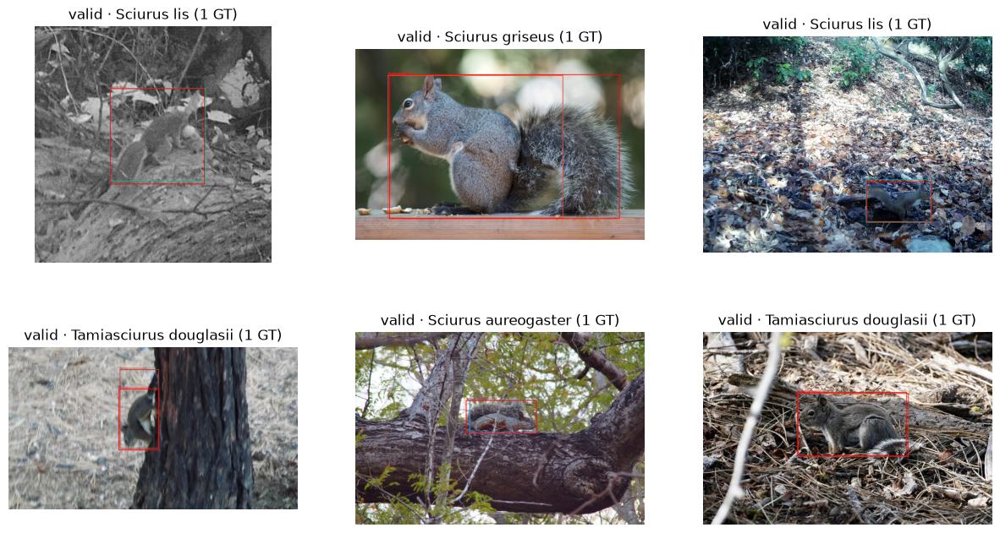

[2026-09-26 17:00:34] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 45, monitor=val/mAP_50_95, value=0.662952)
Epoch 46/50: val mAP=0.6630; peak VRAM=4.07 GiB


[2026-09-26 17:06:49] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 46, monitor=val/mAP_50_95, value=0.664907)
Epoch 47/50: val mAP=0.6649; peak VRAM=4.07 GiB


[2026-09-26 17:13:03] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 47, monitor=val/mAP_50_95, value=0.665977)
Epoch 48/50: val mAP=0.6660; peak VRAM=4.07 GiB


[2026-09-26 17:19:19] [INFO] rf-detr - Best regular checkpoint saved to /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_regular.pth (epoch 48, monitor=val/mAP_50_95, value=0.667393)
Epoch 49/50: val mAP=0.6674; peak VRAM=4.07 GiB


Epoch 50/50: val mAP=0.6666; peak VRAM=4.07 GiB


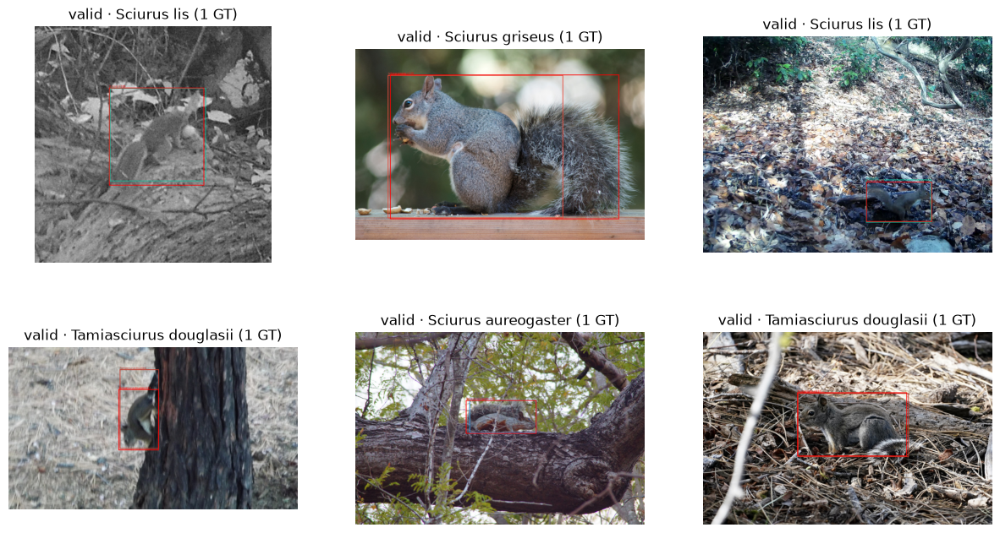

`Trainer.fit` stopped: `max_epochs=50` reached.


[2026-09-26 17:25:38] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.6674, ema=0.6708)


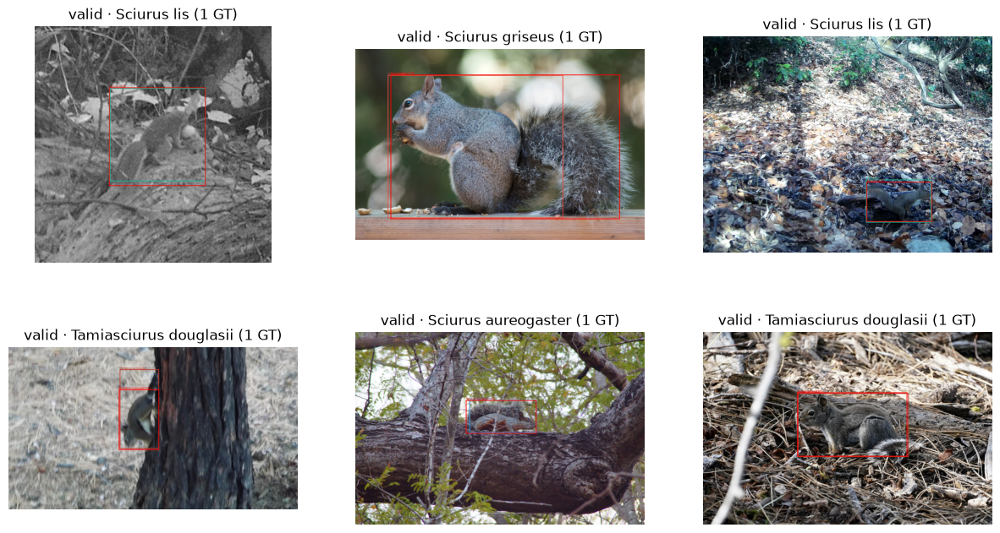

Training successfully finished. Best weights: /home/ss3813/github/ML/CSCI-635-ML-Project/output/runs/20260926T153802Z-v2-f35e9e/checkpoint_best_total.pth


In [9]:
# Full training run (50 epochs)
assert AUDIT_PASSED
assert not (RUN / "training_complete.json").exists(), "Training already complete; continue with evaluation."

with safe_stage("training"):
    seed_everything(CFG["seed"], workers=True)
    module, dm, trainer = make_training(selected["batch_size"], selected["grad_accum_steps"], RUN)
    if not RESUME_RUN:
        module.to("cuda")
        render_progress(module, 0)
    trainer.fit(module, datamodule=dm, ckpt_path=str(RUN / "last.ckpt") if RESUME_RUN else None)
    render_progress(module, int(trainer.current_epoch))
    best_path = RUN / "checkpoint_best_total.pth"
    assert best_path.exists(), "No best checkpoint was produced."
    del module, dm, trainer; gc.collect(); torch.cuda.empty_cache()
    save_json(RUN / "training_complete.json", {"best_checkpoint": best_path.name, "sha256": sha256(best_path), "max_epochs": CFG["epochs"]})
    print("Training successfully finished. Best weights:", best_path)


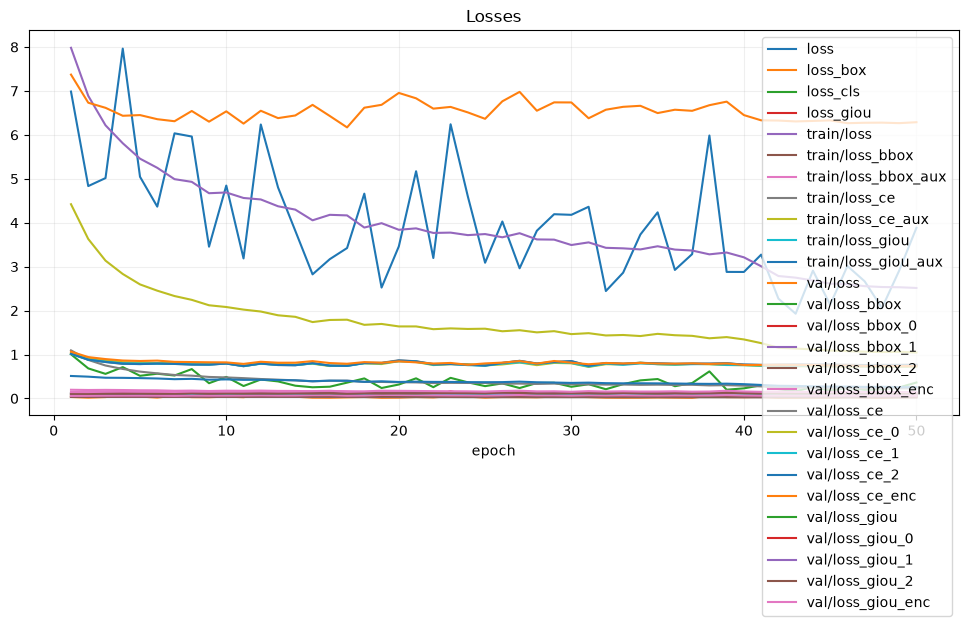

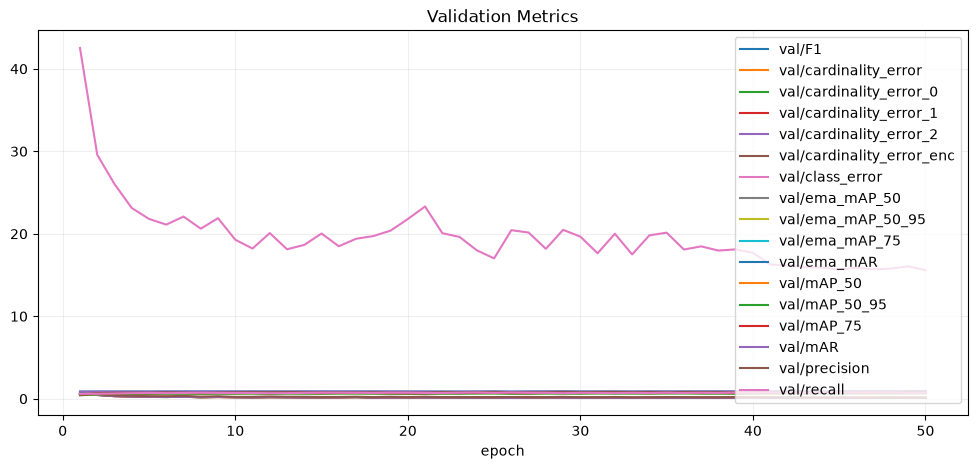

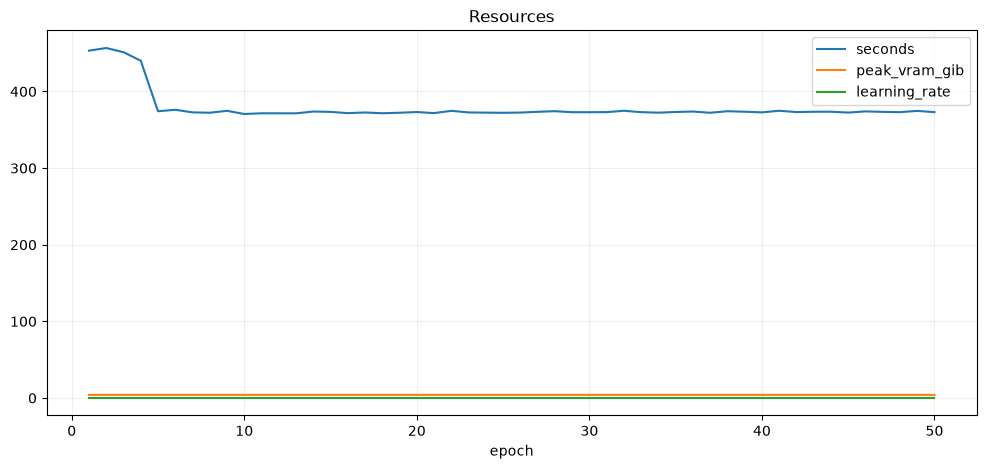

Training history saved.


In [10]:
# Learning curves and loss components
history = pd.DataFrame([json.loads(line) for line in (RUN / "history.jsonl").read_text().splitlines()])
history = history.drop_duplicates("epoch", keep="last").set_index("epoch")
csv_path = RUN / "metrics.csv"
if csv_path.exists():
    csv_metrics = pd.read_csv(csv_path)
    csv_metrics = csv_metrics.dropna(subset=["epoch"])
    csv_metrics["epoch"] = csv_metrics["epoch"].astype(int) + 1
    complete = csv_metrics.groupby("epoch").last().drop(columns=["step"], errors="ignore")
    history = complete.combine_first(history)
history = history.sort_index().reset_index()

for _, row in history.iterrows():
    for key, value in row.items():
        if key != "epoch" and pd.notna(value): emit_scalar("epoch_summary", key, value, int(row["epoch"]))

history.to_csv(REPORT / "training_history.csv", index=False)
for name, columns in [("losses", [c for c in history if "loss" in c]),
                      ("validation_metrics", [c for c in history if c.startswith("val/") and "loss" not in c]),
                      ("resources", ["seconds", "peak_vram_gib", "learning_rate"])]:
    if columns:
        fig, ax = plt.subplots(figsize=(12, 5))
        history.plot(x="epoch", y=columns, ax=ax)
        ax.set_title(name.replace("_", " ").title())
        ax.grid(alpha=0.2)
        save_figure(fig, "training_" + name)

upload_artifact("training-history", REPORT / "training_history.csv")
print("Training history saved.")


## 6. Multiclass detection evaluation, threshold tuning, and test set scoring
Predictions are generated with the best model checkpoint. Standard COCO mAP (mAP@0.50:0.95 and AP50) is evaluated across all 11 classes.
A multiclass confusion matrix evaluates classification accuracy among matched detections.


In [11]:
def box_iou(a, b):
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1]); x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    union = max(0, a[2] - a[0]) * max(0, a[3] - a[1]) + max(0, b[2] - b[0]) * max(0, b[3] - b[1]) - intersection
    return intersection / union if union > 0 else 0.0

def match_multiclass_detections(gt, predictions, threshold, iou=0.5):
    used = set()
    tp = fp = 0
    matched_ious = []
    confusion_pairs = []

    for p in sorted(predictions, key=lambda p: -p["score"]):
        if p["score"] < threshold: continue
        candidates = [(box_iou(p["box"], g["box"]), i, g) for i, g in enumerate(gt) if i not in used]
        overlap, index, matched_g = max(candidates, default=(0, None, None))
        if index is not None and overlap >= iou:
            used.add(index)
            matched_ious.append(overlap)
            confusion_pairs.append((matched_g["class_name"], p.get("class_name", "unknown")))
            if p.get("category_id") == matched_g.get("category_id"):
                tp += 1
            else:
                fp += 1  # Wrong species: one false positive and one missed ground-truth class.
        else:
            fp += 1
            confusion_pairs.append(("background", p.get("class_name", "unknown")))

    for i, g in enumerate(gt):
        if i not in used:
            confusion_pairs.append((g["class_name"], "background"))

    fn = len(gt) - tp
    return tp, fp, fn, matched_ious, confusion_pairs

def detection_metrics(rows, predictions, threshold):
    tp = fp = fn = 0
    ious = []
    for row in rows:
        a, b, c, d, _ = match_multiclass_detections(row["gt"], predictions.get(row["image_id"], []), threshold, CFG["iou"])
        tp += a; fp += b; fn += c; ious.extend(d)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, precision=precision, recall=recall, f1=f1,
                mean_matched_iou=float(np.mean(ious)) if ious else None)

print("Multiclass evaluation helpers loaded.")


Multiclass evaluation helpers loaded.


[2026-09-26 17:25:47] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-26 17:25:47] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-26 17:25:47] [WARNING] rf-detr - Checkpoint has 11 classes but model is configured for 90. Using checkpoint class count (11). Pass num_classes=11 to suppress this warning.
[2026-09-26 17:25:48] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


creating index...
index created!
Loading and preparing results...
DONE (t=0.09s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=3.04s).
Accumulating evaluation results...
DONE (t=1.22s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.671
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.818
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.743
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.107
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.354
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.712
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.740
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.860
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.868
 Average Recall     (AR) @[ IoU=0.5

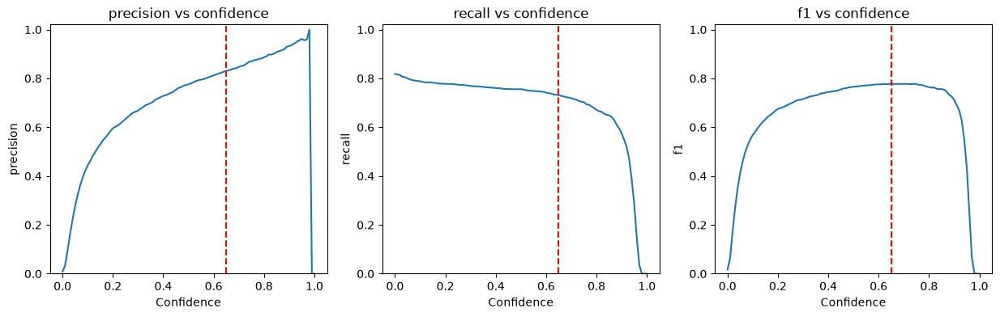

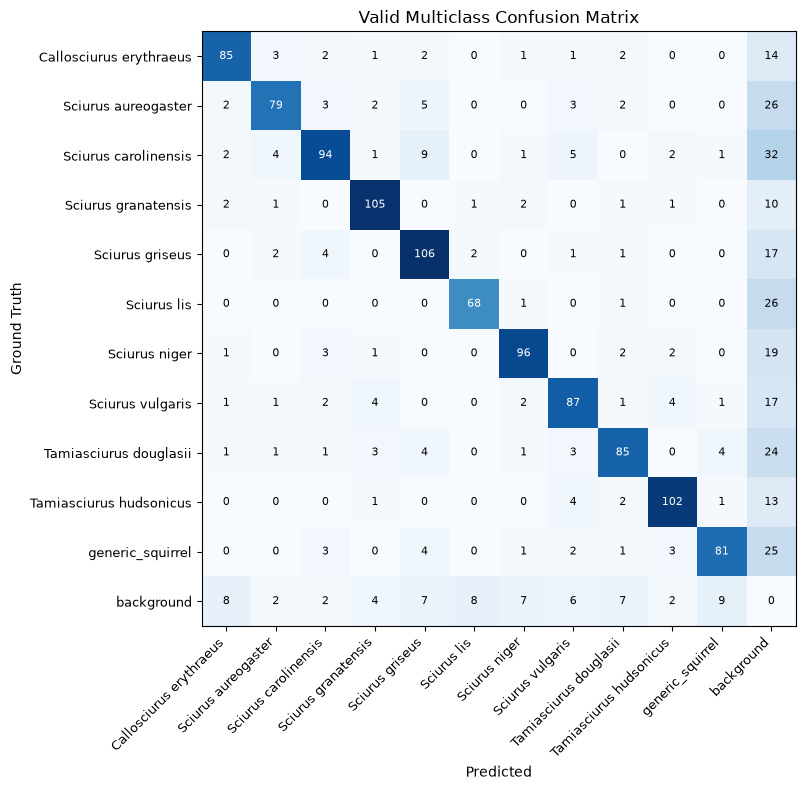

############################### 100% | 32.21/32.21 MB [00:00<00:00, 70.06MB/s]: 


Optimal validation confidence threshold: 0.65
Validation COCO mAP 50:95: 0.6711077051304786


In [12]:
def predict_split(model, split):
    rows = [r for r in records if r["split"] == split]
    predictions = {}
    durations = []
    # Warmup
    model.predict(Image.open(rows[0]["path"]).convert("RGB"), threshold=CFG["prediction_floor"])
    for row in rows:
        im = Image.open(row["path"]).convert("RGB")
        torch.cuda.synchronize(); start = time.perf_counter()
        det = model.predict(im, threshold=CFG["prediction_floor"])
        torch.cuda.synchronize(); durations.append(time.perf_counter() - start)
        pred = []
        for box, score, label in zip(det.xyxy, det.confidence, det.class_id):
            lid = int(label)
            cname = CLASS_NAMES[lid] if lid < len(CLASS_NAMES) else f"cls_{lid}"
            # map model 0-based label back to 1-based COCO category_id
            pred.append(dict(box=[float(x) for x in box], score=float(score), label=lid,
                             category_id=lid + 1, class_name=cname))
        predictions[row["image_id"]] = sorted(pred, key=lambda p: -p["score"])[:CFG["max_detections"]]

    directory = REPORT / split
    directory.mkdir(parents=True, exist_ok=True)
    save_json(directory / "predictions.json", {str(k): v for k, v in predictions.items()})
    return rows, predictions, dict(mean_ms=float(np.mean(durations)*1000), p95_ms=float(np.percentile(durations, 95)*1000))

def coco_metrics(split, rows, predictions):
    import copy
    doc = copy.deepcopy(splits[split])
    gt = COCO()
    gt.dataset = doc
    gt.createIndex()
    detections = []
    for row in rows:
        for p in predictions[row["image_id"]]:
            x1, y1, x2, y2 = p["box"]
            detections.append(dict(image_id=row["image_id"], category_id=p["category_id"],
                                   bbox=[x1, y1, x2 - x1, y2 - y1], score=p["score"]))
    if detections:
        result = gt.loadRes(detections)
    else:
        result = COCO()
        result.dataset = {"images": doc["images"], "categories": doc["categories"], "annotations": []}
        result.createIndex()

    evaluator = COCOeval(gt, result, "bbox")
    evaluator.params.maxDets = [1, 10, 100]
    evaluator.evaluate(); evaluator.accumulate(); evaluator.summarize()
    names = ["mAP_50_95", "AP50", "AP75", "AP_small", "AP_medium", "AP_large",
             "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]
    return {k: float(v) if v >= 0 else None for k, v in zip(names, evaluator.stats)}

def evaluate_report(split, rows, predictions, threshold, latency):
    directory = REPORT / split
    directory.mkdir(parents=True, exist_ok=True)
    thresholds = np.linspace(0, 1, 101)
    curve = pd.DataFrame([dict(threshold=float(t), **detection_metrics(rows, predictions, float(t))) for t in thresholds])
    curve.to_csv(directory / "confidence_curves.csv", index=False)
    operating = detection_metrics(rows, predictions, threshold)
    coco = coco_metrics(split, rows, predictions)

    metrics = dict(split=split, confidence_threshold=threshold, iou_threshold=CFG["iou"],
                   operating=operating, coco=coco, latency=latency)

    # Plot Precision, Recall, F1 vs confidence
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, key in zip(axes, ["precision", "recall", "f1"]):
        ax.plot(curve.threshold, curve[key])
        ax.axvline(threshold, color="red", ls="--")
        ax.set(xlabel="Confidence", ylabel=key, title=f"{key} vs confidence", ylim=(0, 1.02))
    save_figure(fig, "precision_recall_f1_confidence", directory)

    # Multiclass confusion matrix
    all_pairs = []
    for row in rows:
        _, _, _, _, pairs_list = match_multiclass_detections(row["gt"], predictions[row["image_id"]], threshold)
        all_pairs.extend(pairs_list)

    labels = [*CLASS_NAMES, "background"]
    y_true = [p[0] for p in all_pairs]
    y_pred = [p[1] for p in all_pairs]
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    fig, ax = plt.subplots(figsize=(10, 8))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels)))
    ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Ground Truth")
    ax.set_title(f"{split.title()} Multiclass Confusion Matrix")
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=8)
    fig.tight_layout()
    save_figure(fig, "multiclass_confusion_matrix", directory)

    save_json(directory / "metrics.json", metrics)
    html_report(directory, f"{split.title()} Multiclass Evaluation", metrics)
    for name, value in metrics["coco"].items():
        if value is not None: emit_scalar(split, name, value, 0)
    for name, value in operating.items():
        if value is not None: emit_scalar(split, name, value, 0)
    for path in directory.iterdir(): upload_artifact(f"{split}-{path.name}", path)
    return metrics

with safe_stage("validation"):
    best_path = RUN / "checkpoint_best_total.pth"
    assert (RUN / "training_complete.json").exists(), "Complete training before evaluation."
    model = RFDETRMedium(pretrain_weights=str(best_path), device="cuda")
    val_rows, val_predictions, val_latency = predict_split(model, "valid")
    candidates = [(detection_metrics(val_rows, val_predictions, float(t))["f1"], float(t)) for t in np.linspace(0, 1, 101)]
    _, threshold = max(candidates)
    save_json(RUN / "decision_threshold.json", {
        "threshold": threshold,
        "selection": "maximum validation F1 at IoU 0.50; ties choose highest",
        "checkpoint_sha256": sha256(best_path)
    })
    validation_metrics = evaluate_report("valid", val_rows, val_predictions, threshold, val_latency)
    print("Optimal validation confidence threshold:", threshold)
    print("Validation COCO mAP 50:95:", validation_metrics["coco"]["mAP_50_95"])


creating index...
index created!
Loading and preparing results...
DONE (t=0.61s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=2.46s).
Accumulating evaluation results...
DONE (t=1.26s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.661
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.809
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.734
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.171
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.360
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.694
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.723
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.855
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.866
 Average Recall     (AR) @[ IoU=0.5

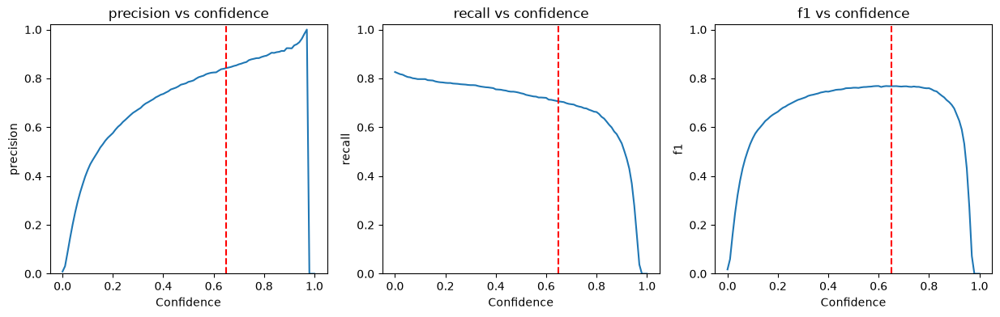

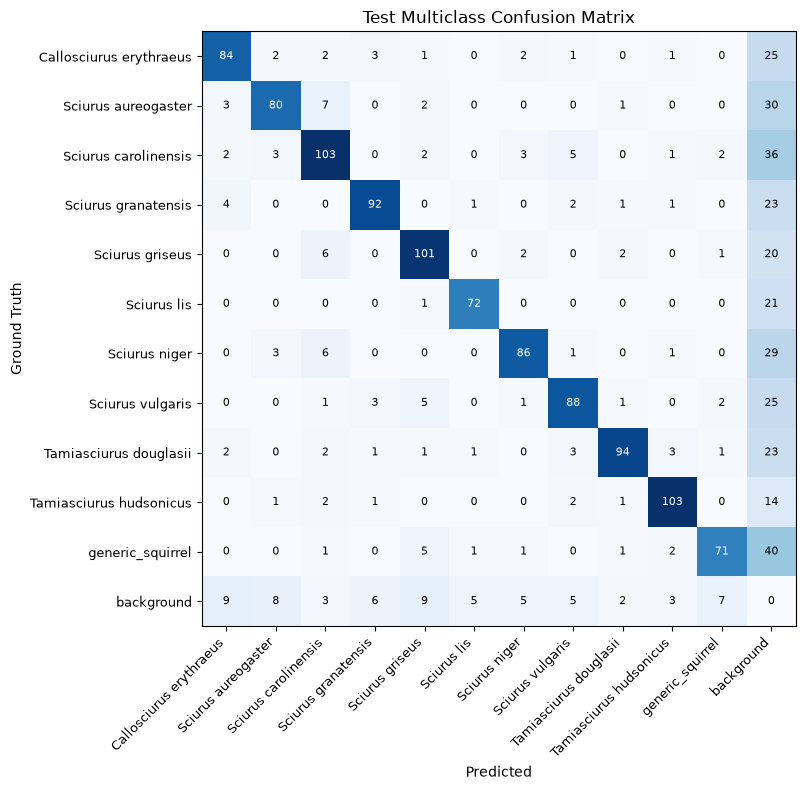

############################### 100% | 32.23/32.23 MB [00:00<00:00, 71.06MB/s]: 


,validation,test
mAP_50_95,0.671108,0.661050
AP50,0.818482,0.809483
AP75,0.742772,0.734369
AP_small,0.106840,0.170529
AP_medium,0.354497,0.359612
AP_large,0.712135,0.693905
AR1,0.739512,0.723365
AR10,0.860019,0.854644
AR100,0.868423,0.866303
AR_small,0.400000,0.519048


Test set evaluation complete.


In [13]:
# Held-out test set evaluation (frozen checkpoint and threshold)
with safe_stage("test evaluation"):
    decision = json.loads((RUN / "decision_threshold.json").read_text())
    assert decision["checkpoint_sha256"] == sha256(best_path)
    threshold = decision["threshold"]
    test_rows, test_predictions, test_latency = predict_split(model, "test")
    test_metrics = evaluate_report("test", test_rows, test_predictions, threshold, test_latency)
    comparison = pd.DataFrame({"validation": validation_metrics["coco"], "test": test_metrics["coco"]})
    comparison.to_csv(REPORT / "validation_test_comparison.csv")
    display(comparison)
    html_report(REPORT, "Squirrel Multiclass Detection — Final Report", {
        "dataset": eda_summary,
        "validation": validation_metrics,
        "test": test_metrics,
        "subreports": ["valid/report.html", "test/report.html"],
    })
    print("Test set evaluation complete.")


## 7. Model export, packaging, and inference demonstration
Exports final weights with multiclass metadata, class enumeration, and test report.


In [14]:
with safe_stage("export"):
    destination = ROOT / "output/model_weights"
    destination.mkdir(parents=True, exist_ok=True)
    target = destination / "best_squirrel_v2_multiclass_rfdetr_medium.pth"

    if target.exists():
        archive_dir = destination / "previous" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        archive_dir.mkdir(parents=True, exist_ok=True)
        for p in destination.iterdir():
            if p.is_file(): shutil.copy2(p, archive_dir / p.name)

    shutil.copy2(best_path, target)
    assert sha256(target) == sha256(best_path)

    sample = Image.open(val_rows[0]["path"]).convert("RGB")
    original = model.predict(sample, threshold=threshold)
    del model; gc.collect(); torch.cuda.empty_cache()

    exported = RFDETRMedium(pretrain_weights=str(target), device="cuda")
    reloaded = exported.predict(sample, threshold=threshold)
    np.testing.assert_allclose(original.xyxy, reloaded.xyxy, rtol=1e-4, atol=1e-3)
    np.testing.assert_allclose(original.confidence, reloaded.confidence, rtol=1e-4, atol=1e-5)
    np.testing.assert_array_equal(original.class_id, reloaded.class_id)

    checkpoint = torch.load(best_path, map_location="cpu", weights_only=False)
    class_mapping = {str(i): name for i, name in enumerate(CLASS_NAMES)}

    metadata = dict(
        model="RFDETRMedium",
        num_classes=len(CLASS_NAMES),
        class_mapping=class_mapping,
        resolution=CFG["resolution"],
        confidence_threshold=threshold,
        epoch_zero_based=checkpoint.get("epoch"),
        dataset=manifest,
        environment=environment,
        selected_batch=selected,
        validation=validation_metrics,
        test=test_metrics,
        sha256=sha256(target),
        clearml_task_id=task.id if task else None,
        run_directory=str(RUN)
    )
    del checkpoint
    classes_str = ", ".join(CLASS_NAMES)
    val_map = validation_metrics["coco"]["mAP_50_95"]
    test_map = test_metrics["coco"]["mAP_50_95"]
    model_card = (
        "# Squirrel Multiclass Detection Model (v2)\\n"
        f"RF-DETR Medium trained on Squirrel Dataset v2 with 11 classes:\\n{classes_str}\\n\\n"
        f"- Total Images: 8,584\\n"
        f"- Split: Leak-free group-stratified 70:15:15\\n"
        f"- Best Validation mAP (50:95): {val_map:.4f}\\n"
        f"- Best Test mAP (50:95): {test_map:.4f}\\n"
        f"- Decision Threshold: {threshold:.2f}\\n"
    )
    (destination / "MODEL_CARD_V2.md").write_text(model_card)
    upload_artifact("model-metadata", destination / "model_metadata_v2.json")

    if task:
        output_model = OutputModel(task=task, framework="PyTorch", name="Squirrel Multiclass RF-DETR Medium v2",
                                   label_enumeration={name: i for i, name in enumerate(CLASS_NAMES)})
        output_model.update_weights(weights_filename=str(target), auto_delete_file=False)

    for path in REPORT.glob("*"):
        if path.is_file(): upload_artifact("report-" + path.name, path)

    report_zip = RUN / "reports.zip"
    with zipfile.ZipFile(report_zip, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
        for asset in REPORT.rglob("*"):
            if asset.is_file():
                if asset.suffix in {".json", ".jsonl", ".csv", ".html", ".log", ".txt"}:
                    assert_secret_free(asset.read_text())
                bundle.write(asset, asset.relative_to(REPORT))
    upload_artifact("complete-reports", report_zip)

    if task:
        task.flush(wait_for_uploads=True)
        task.close()

    save_json(RUN / "workflow_complete.json", {"weights": str(target), "sha256": sha256(target)})
    print("Model export and metadata verification complete:", target)


[2026-09-26 17:27:15] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-26 17:27:15] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-09-26 17:27:15] [WARNING] rf-detr - Checkpoint has 11 classes but model is configured for 90. Using checkpoint class count (11). Pass num_classes=11 to suppress this warning.
[2026-09-26 17:27:15] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).
############################## 100% | 127.70/127.7 MB [00:01<00:00, 79.25MB/s]: 
############################### 100% | 42.64/42.64 MB [00:00<00:00, 75.77MB/s]: 


Model export and metadata verification complete: /home/ss3813/github/ML/CSCI-635-ML-Project/output/model_weights/best_squirrel_v2_multiclass_rfdetr_medium.pth


Detected 1 squirrel(s) in 4a919b5b75974db2693e.jpg:
  - Sciurus griseus: score 0.717 at box [435.0740051269531, 113.41154479980469, 702.7918701171875, 296.07574462890625]


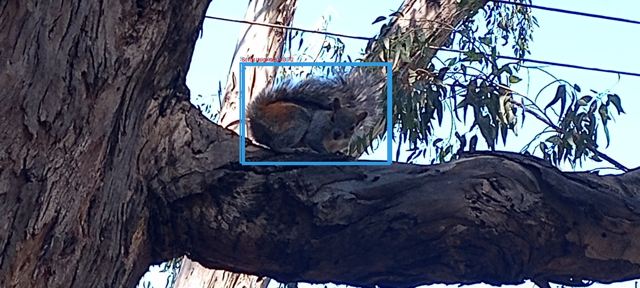

In [377]:
# Inference demonstration on held-out validation sample
import random
index = random.randint(0, len(val_rows) - 1)
IMAGE_PATH = Path(val_rows[index]["path"])
with safe_stage("exported-model inference"):
    detections = exported.predict(Image.open(IMAGE_PATH).convert("RGB"), threshold=threshold)
    preview = {"path": str(IMAGE_PATH), "gt": val_rows[index]["gt"]}
    preds = []
    for b, s, l in zip(detections.xyxy, detections.confidence, detections.class_id):
        lid = int(l)
        cname = CLASS_NAMES[lid] if lid < len(CLASS_NAMES) else f"cls_{lid}"
        preds.append(dict(box=b.tolist(), score=float(s), label=lid, class_name=cname))

    print(f"Detected {len(preds)} squirrel(s) in {IMAGE_PATH.name}:")
    for p in preds:
        print(f"  - {p['class_name']}: score {p['score']:.3f} at box {p['box']}")
    display(draw_sample(preview, preds, threshold))


## References and Documentation
- **RF-DETR**: [Roboflow RF-DETR Documentation](https://rfdetr.roboflow.com/)
- **COCO Format**: [COCO Data Format Specification](https://cocodataset.org/#format-data)
- **ClearML**: [ClearML Python SDK](https://clear.ml/docs/latest/docs/references/sdk/task/)
